# U.S. Obesity and Food Environment Analysis

**Team:** B09 - Bhavya Kandhari, Zoya Salman, Danyang Qin (Lucy), Sanjay Kumar, Dylan Rubenstein

**Data sources:**
- CDC BRFSS Obesity Data (2011–2024) https://catalog.data.gov/dataset/nutrition-physical-activity-and-obesity-behavioral-risk-factor-surveillance-system?from_hint=eyJzb3J0IjoicG9wdWxhcml0eSJ9
- USDA Food Environment Atlas (2025) https://ers.usda.gov/data-products/food-environment-atlas/data-access-and-documentation-downloads (under the current version section)

---

## Table of Contents

1. **Introduction & Motivation**
2. **Data Sources**
3. **Data Description**
4. **Executive Summary**
5. **Setup**
6. **Part A: BRFSS Obesity Data — Cleaning**
   1. Load the BRFSS dataset
   2. Check duplicates, missing values, and column names
   3. Remove rows with missing health measurements
   4. Review stratification categories
   5. Drop unnecessary columns
   6. Create short indicator labels from question IDs
   7. Convert Sample_Size to numeric
   8. Rename columns for easier use
   9. Verify indicator mapping
   10. Sort and finalize
   - Part A Summary
7. **Part B: Food Environment Atlas — Cleaning**
   1. Load food_environment
   2. Placeholder codes
   3. Duplicates check
   4. Check missing FIPS
   5. Missing value overview
   6. Keep the variables we need and add their units
   7. Counties to states
   8. Pivoting: long format to wide format
   9. Readable column names
   10. Checks
   - Part B Summary
   - Merging the datasets
8. **Analysis: Understanding America's Geographic Obesity Divide Beyond Income**
   - Chart 1 — How much has the obesity rate risen from 2011 to 2024?
   - Chart 2 — Which states have the highest and lowest obesity rates?
   - Charts 3 & 4 — Which demographic groups have the highest obesity rates, and does income separate them as much as race, gender and education?
   - Chart 5 — Do high-obesity states differ from low-obesity states at every age, or only among older adults?
   - Chart 6 — Do wealthier states have lower adult obesity rates?
   - Charts 7 & 8 — Does obesity still differ between states when we compare people in the same income bracket?
   - Chart 9 — Which parts of the food environment are associated with adult obesity across states?
   - Charts 10–12 — How do the food environments of West Virginia, Vermont and Colorado differ from the average?
   - Chart 13 — Do higher-income adults in high-obesity states eat and exercise better, and does it show in their obesity rate?
   - Chart 14 — Are the groups least likely to be obese (college graduates, young adults, high earners) still above the national average in the high-obesity states?
   - Chart 15 — How well do food-environment factors alone explain state-level obesity, and which states does the model miss?
9. **Conclusion**
10. **Challenges**
11. **Future Steps**
12. **Risk & Limits**
13. **References**
14. **Generative AI Disclosure**

# Introduction & Motivation

Adult obesity is one of the most widespread and costly public health problems in the United States, linked to type two diabetes, heart disease and certain cancers. Rates are not spread evenly, they differ by state, income, sex, education, age and race . At the same time, the environment a person lives in impacts how easily they can access grocery stores, how many convenience stores are nearby and how many recreational facilities are available.

Our intended audience is a state or regional public-health department (for example, a chronic disease or nutrition division) with a limited budget for food access programs such as SNAP incentives, healthy store incentives and community recreation. Its decision is which states, and then which counties, to prioritise, and what type of program fits each place. Secondary stakeholders are funders (CDC, USDA), county health offices, community organisations and the residents themselves.

We then aim to ask: "How are food environment, socioeconomic status, demographic characteristics and geographic location associated with adult obesity rates across the United States, and where should a public health department place food access programs?"



# Data Sources

- CDC BRFSS Obesity Data (2011–2024) https://catalog.data.gov/dataset/nutrition-physical-activity-and-obesity-behavioral-risk-factor-surveillance-system?from_hint=eyJzb3J0IjoicG9wdWxhcml0eSJ9

- USDA Food Environment Atlas (2025) https://ers.usda.gov/data-products/food-environment-atlas/data-access-and-documentation-downloads (under the current version section)

# Data Description
Our project uses two public datasets. The first data set labelled "BRFSS_Obesity.csv" is the BRFSS Obesity dataset. This dataset comes from the Behavioral Risk Factor Surveillance System, an annual telephone health survey of US adults run by the CDC and published on data.gov. The raw file has 110,880 rows and 33 columns covering 2011-2024 for 55 locations (50 states, DC, three territories and a national row). Each row is one indicator for one place, year and demographic group. The indicators include percent of adults with obesity, overweight and no leisure time physical activity. The groups are total population, income, education, age, sex and race. The main measure is Data_Value.

Our second data set comes as two files labelled "StateandCountyData.csv" and "VariableList.csv" respectively. The dataset comes from the USDA Economic Research Service's Food Environment Atlas, which combines county and state indicators from several federal sources. The "StateandCountyData.csv" has 957,753 rows in long format covering 304 variables for 3156 counties. The "VariableList.csv" file is a data dictionary with one row per variable. It was used to assist us in understanding what each code means, which of the 9 categories it belongs to and its unit.

# Executive Summary

Objectives:
Build a state-level view of adult obesity across the U.S. by combining CDC BRFSS survey data (2011–2024) with USDA Food Environment Atlas indicators.
Identify which demographic groups and states carry the highest obesity burden, and whether the gap between states can be explained by who lives there.
Test how income, the food environment (stores and restaurants per 1,000 people) and physical-activity opportunities relate to obesity, to guide where public-health departments should focus prevention resources.

Key Findings:
Adult obesity rose from 27.4% in 2011 to 33.1% in 2024. In 2022, rates ranged from 24.3% in Washington, DC to 41.0% in West Virginia, with 22 states at 35% or higher, mostly in the South and Appalachia.

The geographic gap appears early and is not explained by age: the highest-obesity states are about 9 points higher among 18–24 year-olds, rising to nearly 14 points by middle age.
Wealthier states have lower obesity (r = −0.71), yet adults in the same income bracket still have very different obesity rates depending on their state. In high-obesity states, even higher earners, college graduates and young adults remain above the national average.

States with more dollar stores have higher obesity (r = +0.62), while states with more full-service restaurants (r = −0.69) and recreation facilities (r = −0.49) have lower obesity. Low food access among American Indian/Alaska Native residents, children and SNAP households is linked to higher obesity.

Methods:
Data Preparation:
Cleaned the BRFSS dataset from 110,880 rows to 97,666 by removing rows without estimates and unnecessary columns, and created short indicator labels (obesity, physical inactivity, fruit and vegetable intake). Cleaned the Food Environment Atlas (957,753 rows, 304 variables, 3,156 counties) by replacing placeholder codes, removing records with missing FIPS codes, and rolling county values up to state level.

Exploratory Data Analysis (EDA):
Conducted national and state-level EDA using trend lines, ranked bar charts, demographic breakdowns, scatter plots with regression lines and correlation charts. These identified how age, race, education and income relate to obesity, and how high-obesity states differ from low-obesity states.

Integration & Comparison:
Merged the two datasets by state to link food-environment, income and recreation indicators with obesity rates for all 50 states and DC. Compared high-obesity states (West Virginia, Louisiana, Oklahoma) with low-obesity states (Colorado, Vermont, Hawaii) within the same income, education and age groups.

Recommendations:
Prioritise high-obesity states and use the food environment as a warning sign. Start with West Virginia, Louisiana and Oklahoma, then expand to other states with obesity rates of 35% or higher. High dollar-store density and few full-service restaurants can help flag states that need closer attention.

Focus on communities, not just income. Even higher earners in high-obesity states have high obesity rates, so programs should reach whole communities rather than only low-income residents.

Instead of relying on new supermarkets or awareness campaigns alone, combine healthier food options in existing stores (through SNAP incentives and healthy-store programs) with affordable fitness programs, parks and safe walking spaces.
Support the groups and communities with the greatest need.

Tailor programs to Black adults, American Indian/Alaska Native adults, adults aged 45–54 and adults without a high school diploma. Use mobile markets, transportation support and school meal programs to reach Native American residents, children, seniors and SNAP households with low food access.

Start prevention early and work in partnership. The gap between high- and low-obesity states already appears among 18–24 year-olds, so schools, universities and workplaces should help build healthier habits early. Public-health departments should work with the CDC, USDA, local governments, retailers and community organisations to pilot programs before expanding them.

# Setup: Run this cell first

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/780-project/data/'
except ModuleNotFoundError:
    DATA_DIR = './data/'

if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(f'Can not find {DATA_DIR}')

print('Files in data folder:', os.listdir(DATA_DIR))

sns.set_theme(style='whitegrid', font_scale=1.05)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files in data folder: ['VariableList.csv', 'StateAndCountyData.csv', 'BRFSS_Obesity.csv']


In [2]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.dpi": 110})

# One fixed palette, always used in the same order
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
GRAY, LIGHT = "#8c8b86", "#e5e4e0"
UP, DOWN = RED, BLUE   # bars for higher-obesity (positive r) and lower-obesity (negative r) relationships
BLUES = ["#b7d3f6", "#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]  # light -> dark, for ordered groups

INCOME_ORDER = ["Less than $15,000", "$15,000 - $24,999", "$25,000 - $34,999",
                "$35,000 - $49,999", "$50,000 - $74,999", "$75,000 or greater"]
EDU_ORDER = ["Less than high school", "High school graduate",
             "Some college or technical school", "College graduate"]
AGE_ORDER = ["18 - 24", "25 - 34", "35 - 44", "45 - 54", "55 - 64", "65 or older"]
RACE_SHORT = {"Non-Hispanic White": "White (NH)", "Non-Hispanic Black": "Black (NH)",
              "Hispanic": "Hispanic", "Non-Hispanic Asian": "Asian (NH)",
              "NH American Indian/Alaska Native": "Am. Indian / AK Native (NH)",
              "NH Hawaiian/Pacific Islander": "Hawaiian / Pac. Islander (NH)",
              "Non-Hispanic 2 or more races": "2+ races (NH)", "Non-Hispanic Other": "Other (NH)"}
INDICATOR_LABEL = {"obesity": "Obesity", "overweight": "Overweight", "no_activity": "No leisure-time\nactivity",
                   "aerobic_150": "Meets aerobic\nguideline (150 min/wk)", "fruit_lt1_daily": "Fruit < 1x/day",
                   "veg_lt1_daily": "Vegetables < 1x/day"}

def esc(s):
    """Escape $ so matplotlib doesn't treat '$15,000 - $24,999' as math text."""
    return s.replace("$", r"\$")

def national(indicator, group_type, year):
    """National (US) rows for one indicator / stratification / year."""
    d = df[(df["state_abbr"] == "US") & (df["indicator"] == indicator)
           & (df["group_type"] == group_type) & (df["year"] == year)]
    return d[d["group"] != "Data not reported"]

def state_table(year, group_type="Total", group="Total"):
    """One row per state, one column per indicator (50 states + DC)."""
    sub = df[(df["year"] == year) & (df["group_type"] == group_type)
             & (df["group"] == group) & (df["state_abbr"].isin(STATES))]
    return sub.pivot_table(index="state_abbr", columns="indicator", values="value")

def spread_labels(values, min_gap):
    """Nudge y-positions apart so end-of-line labels don't overlap."""
    order = sorted(range(len(values)), key=lambda i: values[i])
    pos = [values[i] for i in order]
    for k in range(1, len(pos)):
        if pos[k] - pos[k - 1] < min_gap:
            pos[k] = pos[k - 1] + min_gap
    out = [0] * len(values)
    for k, i in enumerate(order):
        out[i] = pos[k]
    return out

# Part A: BRFSS Obesity Data — Cleaning

##1. Load the BRFSS dataset

In [3]:
df = pd.read_csv(os.path.join(DATA_DIR, 'BRFSS_Obesity.csv'))
print('Original shape:', df.shape)
df.head()

/tmp/ipykernel_11181/4147397800.py:1: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(os.path.join(DATA_DIR, 'BRFSS_Obesity.csv'))


Original shape: (110880, 33)


,YearStart,YearEnd,LocationAbbr,LocationDesc,Datasource,Class,Topic,Question,Data_Value_Unit,Data_Value_Type,...,GeoLocation,ClassID,TopicID,QuestionID,DataValueTypeID,LocationID,StratificationCategory1,Stratification1,StratificationCategoryId1,StratificationID1
0,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,NaN,Value,...,"(32.840571122, -86.631860762)",OWS,OWS1,Q036,VALUE,1,Income,"$15,000 - $24,999",INC,INC1525
1,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,NaN,Value,...,"(32.840571122, -86.631860762)",OWS,OWS1,Q036,VALUE,1,Income,"$25,000 - $34,999",INC,INC2535
2,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,NaN,Value,...,"(32.840571122, -86.631860762)",OWS,OWS1,Q036,VALUE,1,Income,"$35,000 - $49,999",INC,INC3550
3,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,NaN,Value,...,"(32.840571122, -86.631860762)",OWS,OWS1,Q036,VALUE,1,Income,"$50,000 - $74,999",INC,INC5075
4,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,NaN,Value,...,"(32.840571122, -86.631860762)",OWS,OWS1,Q036,VALUE,1,Income,"$75,000 or greater",INC,INC75PLUS


##2. Check duplicates, missing values, and column names

In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())
print(df.columns.tolist())

df.columns = df.columns.str.strip() #just formatting the columns well

Missing values:
YearStart                          0
YearEnd                            0
LocationAbbr                       0
LocationDesc                       0
Datasource                         0
Class                              0
Topic                              0
Question                           0
Data_Value_Unit               106260
Data_Value_Type                    0
Data_Value                     13214
Data_Value_Alt                 13214
Data_Value_Footnote_Symbol     97666
Data_Value_Footnote            97666
Low_Confidence_Limit           13214
High_Confidence_Limit          13214
Sample_Size                    13214
Total                         106920
Age(years)                     87120
Education                      95040
Sex                           102959
Income                         83160
Race/Ethnicity                 79200
GeoLocation                     2016
ClassID                            0
TopicID                            0
QuestionID            

## 3. Remove rows with missing health measurements

In [5]:
# Remove rows where the health estimate is unavailable
df.loc[df["Data_Value"].isna(),["Data_Value", "Data_Value_Footnote", "Sample_Size"]].head(10)


,Data_Value,Data_Value_Footnote,Sample_Size
13,NaN,Data not available because sample size is insu...,NaN
17,NaN,Data not available because sample size is insu...,NaN
25,NaN,Data not available because sample size is insu...,NaN
41,NaN,Data not available because sample size is insu...,NaN
45,NaN,Data not available because sample size is insu...,NaN
51,NaN,Data not available because sample size is insu...,NaN
73,NaN,Data not available because sample size is insu...,NaN
81,NaN,Data not available because sample size is insu...,NaN
97,NaN,Data not available because sample size is insu...,NaN
101,NaN,Data not available because sample size is insu...,NaN


In [6]:
df = df.dropna(subset=["Data_Value"])
print("Rows remaining:", len(df))
print("Missing Data_Value:", df["Data_Value"].isna().sum())

Rows remaining: 97666
Missing Data_Value: 0


## 4. Review stratification categories

In [7]:
df["StratificationCategory1"].value_counts() #this is what we gonna group by

,count
StratificationCategory1,
Income,26917
Age (years),23076
Race/Ethnicity,20751
Education,15384
Sex,7692
Total,3846


In [8]:
df.groupby("StratificationCategory1")["Stratification1"].unique()

,Stratification1
StratificationCategory1,
Age (years),"[18 - 24, 25 - 34, 35 - 44, 45 - 54, 55 - 64, ..."
Education,"[College graduate, High school graduate, Less ..."
Income,"[$15,000 - $24,999, $25,000 - $34,999, $35,000..."
Race/Ethnicity,"[Non-Hispanic 2 or more races, NH American Ind..."
Sex,"[Female, Male]"
Total,[Total]


## 5. Drop unnecessary columns

In [9]:

df = df.drop(columns=["Total", "Age(years)", "Education", "Sex", "Income", "Race/Ethnicity"], errors="ignore")
df.isnull().sum()

,0
YearStart,0
YearEnd,0
LocationAbbr,0
LocationDesc,0
Datasource,0
Class,0
Topic,0
Question,0
Data_Value_Unit,93505
Data_Value_Type,0


In [10]:
# Drop all four unnecessary columns safely in a single step (this is for geolocation)
df = df.drop(columns=["Data_Value_Unit", "Data_Value_Footnote_Symbol", "Data_Value_Footnote", "GeoLocation"],errors="ignore"
)
df.isnull().sum()
df.shape #THIS IS OUR NEW CLEAN DATASET

(97666, 23)

In [11]:
# Remove spaces from column names
df.columns = df.columns.str.strip()
df.head()


,YearStart,YearEnd,LocationAbbr,LocationDesc,Datasource,Class,Topic,Question,Data_Value_Type,Data_Value,...,Sample_Size,ClassID,TopicID,QuestionID,DataValueTypeID,LocationID,StratificationCategory1,Stratification1,StratificationCategoryId1,StratificationID1
0,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,34.8,...,"1,367",OWS,OWS1,Q036,VALUE,1,Income,"$15,000 - $24,999",INC,INC1525
1,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,35.8,...,757,OWS,OWS1,Q036,VALUE,1,Income,"$25,000 - $34,999",INC,INC2535
2,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,32.3,...,861,OWS,OWS1,Q036,VALUE,1,Income,"$35,000 - $49,999",INC,INC3550
3,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,34.1,...,785,OWS,OWS1,Q036,VALUE,1,Income,"$50,000 - $74,999",INC,INC5075
4,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,28.8,...,"1,125",OWS,OWS1,Q036,VALUE,1,Income,"$75,000 or greater",INC,INC75PLUS


## 6. Create short indicator labels from question IDs

In [12]:
df["Question"].unique()

array(['Percent of adults aged 18 years and older who have obesity',
       'Percent of adults aged 18 years and older who have an overweight classification',
       'Percent of adults who achieve at least 150 minutes a week of moderate-intensity aerobic physical activity or 75 minutes a week of vigorous-intensity aerobic activity (or an equivalent combination)',
       'Percent of adults who achieve at least 150 minutes a week of moderate-intensity aerobic physical activity or 75 minutes a week of vigorous-intensity aerobic physical activity (or an equivalent combination) and engage in muscle-strengthening activities on 2 or more days a week',
       'Percent of adults who achieve more than 300 minutes a week of moderate-intensity aerobic physical activity or 150 minutes a week of vigorous-intensity aerobic activity (or an equivalent combination)',
       'Percent of adults who engage in muscle-strengthening activities on 2 or more days a week',
       'Percent of adults who engage in

In [13]:

for q in df["QuestionID"].unique():
    print(q, ":", df[df["QuestionID"] == q]["Question"].iloc[0])
indicator = {"Q036": "obesity", "Q037": "overweight","Q043": "aerobic_150", "Q044": "aerobic_and_muscle","Q045": "aerobic_300",
"Q046": "muscle_2days","Q047": "no_activity","Q018": "fruit_lt1_daily","Q019": "veg_lt1_daily"}

df["indicator"] = df["QuestionID"].map(indicator)

Q036 : Percent of adults aged 18 years and older who have obesity
Q037 : Percent of adults aged 18 years and older who have an overweight classification
Q043 : Percent of adults who achieve at least 150 minutes a week of moderate-intensity aerobic physical activity or 75 minutes a week of vigorous-intensity aerobic activity (or an equivalent combination)
Q044 : Percent of adults who achieve at least 150 minutes a week of moderate-intensity aerobic physical activity or 75 minutes a week of vigorous-intensity aerobic physical activity (or an equivalent combination) and engage in muscle-strengthening activities on 2 or more days a week
Q045 : Percent of adults who achieve more than 300 minutes a week of moderate-intensity aerobic physical activity or 150 minutes a week of vigorous-intensity aerobic activity (or an equivalent combination)
Q046 : Percent of adults who engage in muscle-strengthening activities on 2 or more days a week
Q047 : Percent of adults who engage in no leisure-time ph

In [14]:
df.head()
df["indicator"].value_counts()

,count
indicator,
no_activity,19141
obesity,19078
overweight,19078
muscle_2days,8078
aerobic_150,8052
aerobic_300,8042
aerobic_and_muscle,8042
fruit_lt1_daily,4080
veg_lt1_daily,4075


## 7. Convert Sample_Size to numeric

In [15]:
df["Sample_Size"] = pd.to_numeric(
    df["Sample_Size"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)
print(df["Sample_Size"].dtype)

int64


## 8. Rename columns for easier use

In [16]:
df = df.rename(columns={"YearStart": "year","LocationAbbr": "state_abbr","LocationDesc": "state",
"Class": "class","Question": "question","QuestionID": "question_id","Data_Value": "value",
"Low_Confidence_Limit": "ci_low", "High_Confidence_Limit": "ci_high","Sample_Size": "sample_size",
"GeoLocation": "geo","StratificationCategory1": "group_type","Stratification1": "group"})

df.head()

,year,YearEnd,state_abbr,state,Datasource,class,Topic,question,Data_Value_Type,value,...,ClassID,TopicID,question_id,DataValueTypeID,LocationID,group_type,group,StratificationCategoryId1,StratificationID1,indicator
0,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,34.8,...,OWS,OWS1,Q036,VALUE,1,Income,"$15,000 - $24,999",INC,INC1525,obesity
1,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,35.8,...,OWS,OWS1,Q036,VALUE,1,Income,"$25,000 - $34,999",INC,INC2535,obesity
2,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,32.3,...,OWS,OWS1,Q036,VALUE,1,Income,"$35,000 - $49,999",INC,INC3550,obesity
3,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,34.1,...,OWS,OWS1,Q036,VALUE,1,Income,"$50,000 - $74,999",INC,INC5075,obesity
4,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,28.8,...,OWS,OWS1,Q036,VALUE,1,Income,"$75,000 or greater",INC,INC75PLUS,obesity


## 9. Verify indicator mapping

In [17]:
indicator = { "Q036": "obesity",
             "Q037": "overweight",
              "Q047": "no_activity",
              "Q043": "aerobic_150",
              "Q044": "aerobic_and_muscle",
              "Q045": "aerobic_300",
              "Q046": "muscle_2days",
              "Q018": "fruit_lt1_daily",
              "Q019": "veg_lt1_daily"}

df["indicator"] = df["question_id"].map(indicator)

# Check the indicators
display(
    df[["question_id", "indicator", "question"]]
    .drop_duplicates()
)

print(df["indicator"].value_counts())

,question_id,indicator,question
0,Q036,obesity,Percent of adults aged 18 years and older who ...
1540,Q037,overweight,Percent of adults aged 18 years and older who ...
3080,Q043,aerobic_150,Percent of adults who achieve at least 150 min...
4620,Q044,aerobic_and_muscle,Percent of adults who achieve at least 150 min...
6160,Q045,aerobic_300,Percent of adults who achieve more than 300 mi...
7700,Q046,muscle_2days,Percent of adults who engage in muscle-strengt...
9240,Q047,no_activity,Percent of adults who engage in no leisure-tim...
46200,Q018,fruit_lt1_daily,Percent of adults who report consuming fruit l...
47740,Q019,veg_lt1_daily,Percent of adults who report consuming vegetab...


indicator
no_activity           19141
obesity               19078
overweight            19078
muscle_2days           8078
aerobic_150            8052
aerobic_300            8042
aerobic_and_muscle     8042
fruit_lt1_daily        4080
veg_lt1_daily          4075
Name: count, dtype: int64


## 10. Sort and Finalize



In [18]:
df = df.sort_values(["group_type", "group"]).reset_index(drop=True) #basically here I just want everything in orderr :)
print('Final BRFSS shape:', df.shape)
df.head()


Final BRFSS shape: (97666, 24)


,year,YearEnd,state_abbr,state,Datasource,class,Topic,question,Data_Value_Type,value,...,ClassID,TopicID,question_id,DataValueTypeID,LocationID,group_type,group,StratificationCategoryId1,StratificationID1,indicator
0,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,16.3,...,OWS,OWS1,Q036,VALUE,1,Age (years),18 - 24,AGEYR,AGEYR1824,obesity
1,2011,2011,AK,Alaska,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,19.8,...,OWS,OWS1,Q036,VALUE,2,Age (years),18 - 24,AGEYR,AGEYR1824,obesity
2,2011,2011,AZ,Arizona,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,18.7,...,OWS,OWS1,Q036,VALUE,4,Age (years),18 - 24,AGEYR,AGEYR1824,obesity
3,2011,2011,AR,Arkansas,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,23.0,...,OWS,OWS1,Q036,VALUE,5,Age (years),18 - 24,AGEYR,AGEYR1824,obesity
4,2011,2011,CA,California,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,14.5,...,OWS,OWS1,Q036,VALUE,6,Age (years),18 - 24,AGEYR,AGEYR1824,obesity


#Part A Summary
Cleaning reduced the BFRSS data from 110,880 rows and 33 columns to 97,666 rows and 24 columns. The main loss was 13,214 rows with no estimate due to small samples, and no duplicates were found. The data now has readible labels and numeric fields.

---
# Part B: Food Environment Atlas — Cleaning

##1. Load food_environment

In [19]:
data = pd.read_csv(DATA_DIR + 'StateAndCountyData.csv')
varlist = pd.read_csv(DATA_DIR + 'VariableList.csv')

print('data:',data.shape)
print('Counties:',data['FIPS'].nunique())
print('varlist:',varlist.shape)
print('Categories:',varlist['Category_Code'].nunique())

data.head()

data: (957753, 5)
Counties: 3156
varlist: (304, 6)
Categories: 9


,FIPS,State,County,Variable_Code,Value
0,1001.0,AL,Autauga,LACCESS_POP15,18092.66135
1,1001.0,AL,Autauga,LACCESS_POP19,18503.22551
2,1001.0,AL,Autauga,PCH_LACCESS_POP_15_19,2.26923
3,1001.0,AL,Autauga,PCT_LACCESS_POP15,33.15435
4,1001.0,AL,Autauga,PCT_LACCESS_POP19,33.90670


The raw dataset has 957753 rows and 5 columns, covering 3156 counties and 304 variables. The variable dictionary documents 304 variables across 9 categories.

##2. Placeholder codes


 -9999 = not available / not applicable / suppressed
-8888 = the county did not exist in that year
Both are stored as real numbers, so we converted them to NaN before any average or sum.

In [20]:
# Count how many -9999 and-8888 values exist before cleaning
count_9999 = (data['Value'] == -9999).sum()
count_8888 = (data['Value'] == -8888).sum()
print(
    "Rows with -9999 before:", count_9999,
    "Rows with -8888 before:", count_8888,
    "Rows with NaN already:", data['Value'].isna().sum())


Rows with -9999 before: 86308 Rows with -8888 before: 3951 Rows with NaN already: 0


We found 86308 values coded as -9999 and 3951 as -8888.

In [21]:
# Replace all -9999 and -8888 values with NaN
data['Value'] = data['Value'].replace([-9999,-8888], np.nan)
data = data.reset_index(drop=True)

# Confirm that all -9999 and -8888 values are gone
print('-9999 or -8888 left:', data['Value'].isin([-9999, -8888]).sum())
print('Missing values (NaN) now:', data['Value'].isna().sum())


-9999 or -8888 left: 0
Missing values (NaN) now: 90259


Placeholders represent NaN but would be treated like a real number(e.g. State avg will turn into negative) if we don't convert them into missing values.

##3. Duplicates check

In [22]:
rows_start = data.shape[0]
data = data.drop_duplicates()
n_dups = rows_start - data.shape[0]
print('Duplicate rows removed:', n_dups)

Duplicate rows removed: 0


No duplicate rows were found, so no rows were removed.

##4. Check missing FIPS

In [23]:
display(data[data['FIPS'].isna()].head(20))

# Remove rows where FIPS is missing
data = data.dropna(subset=['FIPS'])

# Reset the index
data = data.reset_index(drop=True)

# Check that there are now 0 missing FIPS values
print("Missing FIPS:", data['FIPS'].isna().sum())

# Check the size of the cleaned dataset
print("Dataset shape:", data.shape)

,FIPS,State,County,Variable_Code,Value
430834,NaN,AK,Aleutian Islands Area,DIRSALES_FARMS12,NaN
430835,NaN,AK,Aleutian Islands Area,DIRSALES_FARMS17,NaN
430836,NaN,AK,Aleutian Islands Area,PCH_DIRSALES_FARMS_12_17,NaN
430837,NaN,AK,Aleutian Islands Area,PCT_LOCLFARM12,NaN
430838,NaN,AK,Aleutian Islands Area,PCT_LOCLFARM17,NaN
430839,NaN,AK,Aleutian Islands Area,PCT_LOCLSALE12,NaN
430840,NaN,AK,Aleutian Islands Area,PCT_LOCLSALE17,NaN
430841,NaN,AK,Aleutian Islands Area,DIRSALES12,NaN
430842,NaN,AK,Aleutian Islands Area,DIRSALES17,NaN
430843,NaN,AK,Aleutian Islands Area,PCH_DIRSALES_12_17,NaN


Missing FIPS: 0
Dataset shape: (957278, 5)


Rows with missing FIPS codes and were removed. These rows cannot be assigned to any county or state, so they cannot be used in our analysis.

## 5. Missing value overview

In [24]:
# Check how many missing values are in each column
print(data.isna().sum())
data['is_missing'] = data['Value'].isna()

# % missing for each variable
missing_pct = data.groupby('Variable_Code')['is_missing'].mean()
missing_pct = missing_pct.sort_values(ascending=False)
print(missing_pct.head(20))

# % missing for each state
missing_by_state = data.groupby('State')['is_missing'].mean() * 100
print(missing_by_state.sort_values(ascending=False).head(5))

FIPS                 0
State                0
County               0
Variable_Code        0
Value            89989
dtype: int64
Variable_Code
PCH_SUPERC_16_20               0.786896
PCH_SUPERCPTH_16_20            0.786896
SUPERC20                       0.785305
SUPERCPTH20                    0.785305
PCH_SPECS_16_20                0.650763
PCH_SPECSPTH_16_20             0.650763
SPECSPTH20                     0.648537
SPECS20                        0.648537
PCH_RECFAC_16_20               0.589695
PCH_RECFACPTH_16_20            0.589695
RECFAC20                       0.588422
RECFACPTH20                    0.588422
PCH_FRESHVEG_ACRESPTH_12_17    0.568124
PCH_FRESHVEG_ACRES_12_17       0.568124
PCH_AGRITRSM_RCT_12_17         0.491445
PCH_PC_WIC_REDEMP_16_22        0.477598
PCH_REDEMP_WICS_16_22          0.475056
PC_WIC_REDEMP22                0.449635
REDEMP_WICS22                  0.447092
SUPERC16                       0.430025
Name: is_missing, dtype: float64
State
AK    36.737470
CT 

Note: We can see that some variables have high missing rates at the county level (supercenters ~79%, specialty stores ~65%, fitness facilities ~59%), so their state values are based on fewer counties and may be less reliable.

##6. Keep the variables we need and add their units

In [25]:
#Fix the wrong label
wrong_label = (varlist['Units']=='Count')&(varlist['Variable_Code'].str.contains('PTH'))
n_wrong_label = wrong_label.sum()
print('Labeled Count but really per 1,000 people:',
      varlist.loc[wrong_label, 'Variable_Code'].tolist())
varlist.loc[wrong_label,'Units'] = '# per 1,000 pop'

#Keep only the important categories that are related to our topic
important_categories = ['ACCESS', 'STORES', 'RESTAURANTS', 'HEALTH', 'SOCIOECONOMIC']
important_codes = varlist.loc[varlist['Category_Code'].isin(important_categories),'Variable_Code']
data = data[data['Variable_Code'].isin(important_codes)]

#Put new unit on every row
data = data.merge(varlist[['Variable_Code', 'Units']], on = 'Variable_Code', how = 'left')

Labeled Count but really per 1,000 people: ['FSRPTH16', 'FSRPTH20']


We kept 5 categories related to our problem definition (ACCESS, STORES, RESTAURANTS, HEALTH, SOCIOECONOMIC) and dropped the rest. We also fixed variables that were mislabelled as Count but are actually per-1,000 rates.

##7. Counties to states



*   Count (number of stores, people): add up the counties using sum()
*   Percent: average of the counties using mean().


*   Things other than Count and People(% change, Legend, Classification...) is left out: these cannot be averaged across counties.






In [26]:
#Sum the count variables
counts = data[data['Units'] == 'Count']
state_counts = counts.groupby(['State','Variable_Code'])['Value'].sum(min_count=1).reset_index()

#Avg the percentage variables
pct = data[data['Units'].isin(['Percent','# per 1,000 pop','Dollars'])]
state_pct = pct.groupby(['State','Variable_Code'])['Value'].mean().reset_index()


Count columns were summed across counties. Rate and percent columns were averaged. "% change" and other non-aggregable columns were left out.

Note: State values for rates and percentages are simple averages of their counties (not weighted by population), so a small county counts the same as a large one.

##8. Pivoting:long format to wide format

In [27]:
state_long = pd.concat([state_counts,state_pct])
state_wide = state_long.pivot(index='State', columns = "Variable_Code", values = 'Value').reset_index()
eda = state_wide.copy()
eda['PCT_OBESE_ADULTS22'] = eda['PCT_OBESE_ADULTS22'].round(1)
STATES = state_wide["State"].tolist()
print(state_wide.shape)

(51, 111)


The table was reshaped from long format (one row per state-variable pair) to wide format (one row per state, one column per variable). This format is needed for joining with BRFSS and for plotting relationships between variables.

##9. Readable column names

In [28]:

names = varlist['Variable_Name'] + '(' + varlist['Units'] + ')'
code_to_name = dict(zip(varlist['Variable_Code'],names))

state_food_env = state_wide.rename(columns = code_to_name)

Column names were converted from variable codes (e.g. GROCPTH16) to readable names with units (e.g. "Grocery stores/1,000 pop, 2016"). This makes the table easier to interpret for the audience.

##10.Checks

In [29]:
state_food_env.describe()
state_food_env.shape

(51, 111)

In [30]:
print('State numbers',state_food_env['State'].nunique(),'Should be 51')

State numbers 51 Should be 51


#Part B Summary
The atlas data went from 957,553 rows to a state-level table of 51 rows and 111 columns. The most important fix was converting the placeholder codes to missing valuess. Some variables rest on a few counties, so they should be interpreted with care.

##Merging the datasets


In [31]:

# Merge Dataset 1 (BRFSS) with Dataset 2 (USDA)

df.head(100)

merged_df = df.merge(state_wide,left_on="state_abbr",right_on="State",how="left",validate="many_to_one",indicator=True)

print("BRFSS rows:", len(df))
print("Merged rows:", len(merged_df))
print(merged_df["_merge"].value_counts())

print(merged_df.columns.tolist())

merged_df.head()

# Get descriptions of all Atlas columns
column_info = varlist[
    ["Variable_Code", "Variable_Name",
     "Category_Code", "Units"]
]

# Keep columns that are in our merged dataset
column_info = column_info[
    column_info["Variable_Code"].isin(merged_df.columns)
]

# Display all descriptions
display(column_info)

merged_df[merged_df["_merge"] == "left_only"]["state"].value_counts()

analysis_base = merged_df[
    merged_df["_merge"] == "both"
].copy()

print(analysis_base.shape)


#overall adult and obesity rate for each state

analysis_df = analysis_base[(analysis_base["year"] == 2022) & (analysis_base["indicator"] == "obesity") & (analysis_base["group_type"] == "Total")].copy()

print(analysis_df.shape)

print(analysis_df["state"].nunique())

print(analysis_df["state"].value_counts())

cols = [
    "state",
    "value",
    "GROCPTH20",
    "FFRPTH20",
    "POVRATE21"
]

analysis_df = analysis_df[cols].copy()

analysis_df.head()


analysis_df.describe()


BRFSS rows: 97666
Merged rows: 97666
_merge
both          92590
left_only      5076
right_only        0
Name: count, dtype: int64
['year', 'YearEnd', 'state_abbr', 'state', 'Datasource', 'class', 'Topic', 'question', 'Data_Value_Type', 'value', 'Data_Value_Alt', 'ci_low', 'ci_high', 'sample_size', 'ClassID', 'TopicID', 'question_id', 'DataValueTypeID', 'LocationID', 'group_type', 'group', 'StratificationCategoryId1', 'StratificationID1', 'indicator', 'State', 'CHILDPOVRATE21', 'CONVS16', 'CONVS20', 'CONVSPTH16', 'CONVSPTH20', 'DEEPCHILDPOVRATE21', 'DEEPPOVRATE21', 'DS20', 'DSPTH20', 'FFR16', 'FFR20', 'FFRPTH16', 'FFRPTH20', 'FSR16', 'FSR20', 'FSRPTH16', 'FSRPTH20', 'GROC16', 'GROC20', 'GROCPTH16', 'GROCPTH20', 'LACCESS_AIAN15', 'LACCESS_AIAN19', 'LACCESS_ASIAN15', 'LACCESS_ASIAN19', 'LACCESS_BLACK15', 'LACCESS_BLACK19', 'LACCESS_CHILD15', 'LACCESS_CHILD19', 'LACCESS_HHNV15', 'LACCESS_HHNV19', 'LACCESS_HISP15', 'LACCESS_HISP19', 'LACCESS_HOPI15', 'LACCESS_HOPI19', 'LACCESS_LOWI15', 'LAC

,Variable_Code,Variable_Name,Category_Code,Units
0,LACCESS_POP15,"Population, low access to store, 2015",ACCESS,Count
1,LACCESS_POP19,"Population, low access to store, 2019",ACCESS,Count
3,PCT_LACCESS_POP15,"Population, low access to store (%), 2015",ACCESS,Percent
4,PCT_LACCESS_POP19,"Population, low access to store (%), 2019",ACCESS,Percent
5,LACCESS_LOWI15,"Low income & low access to store, 2015",ACCESS,Count
...,...,...,...,...
296,MEDHHINC21,"Median household income, 2021",SOCIOECONOMIC,Dollars
297,POVRATE21,"Poverty rate, 2021",SOCIOECONOMIC,Percent
298,DEEPPOVRATE21,"Deep poverty rate, 2021",SOCIOECONOMIC,Percent
300,CHILDPOVRATE21,"Child poverty rate, 2021",SOCIOECONOMIC,Percent


(92590, 136)
(51, 136)
51
state
Alabama                 1
Alaska                  1
Arizona                 1
Arkansas                1
California              1
Colorado                1
Connecticut             1
Delaware                1
District of Columbia    1
Florida                 1
Georgia                 1
Hawaii                  1
Idaho                   1
Illinois                1
Indiana                 1
Iowa                    1
Kansas                  1
Kentucky                1
Louisiana               1
Maine                   1
Maryland                1
Massachusetts           1
Michigan                1
Minnesota               1
Mississippi             1
Missouri                1
Montana                 1
Nebraska                1
Nevada                  1
New Hampshire           1
New Jersey              1
New Mexico              1
New York                1
North Carolina          1
North Dakota            1
Ohio                    1
Oklahoma                1
Oregon

,value,GROCPTH20,FFRPTH20,POVRATE21
count,51.000000,51.000000,51.000000,51.000000
mean,33.762745,0.247686,0.698930,13.824333
std,4.056795,0.125247,0.120056,3.386628
min,24.300000,0.129346,0.528822,8.510000
25%,31.000000,0.178803,0.624962,11.253442
50%,33.600000,0.212530,0.684814,12.935227
75%,37.200000,0.258384,0.730155,15.884004
max,41.000000,0.899544,1.160187,22.253659


In [32]:
print("Merged dataset shape:", merged_df.shape)
print("\nMissing values:")
print(merged_df.isnull().sum().sort_values(ascending=False).head(15))

print("\nMerge results:")
print(merged_df["_merge"].value_counts())

Merged dataset shape: (97666, 136)

Missing values:
PCT_HSPA21               18051
WICSPTH22                 6948
SNAPSPTH23                6948
PCT_DIABETES_ADULTS19     6728
FFRPTH16                  5076
FFRPTH20                  5076
FSR16                     5076
FSR20                     5076
PCT_LACCESS_WHITE15       5076
PCT_LACCESS_SNAP19        5076
PCT_LACCESS_WHITE19       5076
PCT_NHASIAN20             5076
PCT_NHOR20                5076
PCT_NHPI20                5076
PCT_NHBLACK20             5076
dtype: int64

Merge results:
_merge
both          92590
left_only      5076
right_only        0
Name: count, dtype: int64


In [33]:
# Keep only records matched across both datasets dropping the above states Guam, Puerto Rico, National and Virgin Island
matched_df = merged_df.loc[
    merged_df["_merge"] == "both"].copy()

print("Original rows:", len(merged_df))
print("Matched rows:", len(matched_df))
print("States matched:", matched_df["state_abbr"].nunique())

display(matched_df.head())
matched_df.columns.tolist()

Original rows: 97666
Matched rows: 92590
States matched: 51


,year,YearEnd,state_abbr,state,Datasource,class,Topic,question,Data_Value_Type,value,...,SPECSPTH20,SUPERC16,SUPERC20,SUPERCPTH16,SUPERCPTH20,WICS16,WICS22,WICSPTH16,WICSPTH22,_merge
0,2011,2011,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,16.3,...,0.051932,127.0,99.0,0.031232,0.032971,722.0,633.0,0.191985,0.150163,both
1,2011,2011,AK,Alaska,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,19.8,...,0.100764,25.0,20.0,0.047731,0.037646,165.0,165.0,0.809854,0.757918,both
2,2011,2011,AZ,Arizona,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,18.7,...,0.054701,151.0,193.0,0.025995,0.028058,878.0,742.0,0.189943,0.179803,both
3,2011,2011,AR,Arkansas,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,23.0,...,0.062937,85.0,94.0,0.040932,0.053558,423.0,384.0,0.168064,0.156684,both
4,2011,2011,CA,California,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,14.5,...,0.086692,295.0,771.0,0.011280,0.022677,4680.0,3982.0,0.153778,0.136279,both


['year',
 'YearEnd',
 'state_abbr',
 'state',
 'Datasource',
 'class',
 'Topic',
 'question',
 'Data_Value_Type',
 'value',
 'Data_Value_Alt',
 'ci_low',
 'ci_high',
 'sample_size',
 'ClassID',
 'TopicID',
 'question_id',
 'DataValueTypeID',
 'LocationID',
 'group_type',
 'group',
 'StratificationCategoryId1',
 'StratificationID1',
 'indicator',
 'State',
 'CHILDPOVRATE21',
 'CONVS16',
 'CONVS20',
 'CONVSPTH16',
 'CONVSPTH20',
 'DEEPCHILDPOVRATE21',
 'DEEPPOVRATE21',
 'DS20',
 'DSPTH20',
 'FFR16',
 'FFR20',
 'FFRPTH16',
 'FFRPTH20',
 'FSR16',
 'FSR20',
 'FSRPTH16',
 'FSRPTH20',
 'GROC16',
 'GROC20',
 'GROCPTH16',
 'GROCPTH20',
 'LACCESS_AIAN15',
 'LACCESS_AIAN19',
 'LACCESS_ASIAN15',
 'LACCESS_ASIAN19',
 'LACCESS_BLACK15',
 'LACCESS_BLACK19',
 'LACCESS_CHILD15',
 'LACCESS_CHILD19',
 'LACCESS_HHNV15',
 'LACCESS_HHNV19',
 'LACCESS_HISP15',
 'LACCESS_HISP19',
 'LACCESS_HOPI15',
 'LACCESS_HOPI19',
 'LACCESS_LOWI15',
 'LACCESS_LOWI19',
 'LACCESS_MULTIR15',
 'LACCESS_MULTIR19',
 'LACCESS_POP

In [34]:
unmatched = merged_df.loc[merged_df["_merge"] == "left_only",["state_abbr", "state"]]

print("Unmatched states:")
print(unmatched.drop_duplicates().sort_values("state_abbr"))

print("\nRows per unmatched state:")
print(unmatched["state_abbr"].value_counts())

Unmatched states:
     state_abbr           state
938          GU            Guam
572          PR     Puerto Rico
51           US        National
1480         VI  Virgin Islands

Rows per unmatched state:
state_abbr
US    2013
GU    1375
PR    1197
VI     491
Name: count, dtype: int64


We performed a many-to-one left merge using state abbreviations as the common key. This allowed us to attach state-level food environment indicators from the USDA dataset to each corresponding BRFSS health observation while preserving all original BRFSS records.

In [35]:
state_analysis = matched_df.loc[
    (matched_df["year"] == 2022) &
    (matched_df["indicator"] == "obesity") &
    (matched_df["group_type"] == "Total") &
    (matched_df["group"] == "Total")].copy()

print("Rows:", len(state_analysis))
print("Columns:", len(state_analysis.columns))
display(state_analysis.head())

Rows: 51
Columns: 136


,year,YearEnd,state_abbr,state,Datasource,class,Topic,question,Data_Value_Type,value,...,SPECSPTH20,SUPERC16,SUPERC20,SUPERCPTH16,SUPERCPTH20,WICS16,WICS22,WICSPTH16,WICSPTH22,_merge
96968,2022,2022,AL,Alabama,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,38.3,...,0.051932,127.0,99.0,0.031232,0.032971,722.0,633.0,0.191985,0.150163,both
96969,2022,2022,AK,Alaska,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,32.1,...,0.100764,25.0,20.0,0.047731,0.037646,165.0,165.0,0.809854,0.757918,both
96970,2022,2022,AZ,Arizona,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,33.2,...,0.054701,151.0,193.0,0.025995,0.028058,878.0,742.0,0.189943,0.179803,both
96971,2022,2022,AR,Arkansas,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,37.4,...,0.062937,85.0,94.0,0.040932,0.053558,423.0,384.0,0.168064,0.156684,both
96972,2022,2022,CA,California,Behavioral Risk Factor Surveillance System,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,28.1,...,0.086692,295.0,771.0,0.011280,0.022677,4680.0,3982.0,0.153778,0.136279,both


In [36]:
# Rename columns to make them easier to understand

state_analysis = state_analysis.rename(columns={
    # State information
    "state_abbr": "state_code",
    "value": "obesity_rate",

    # Food environment
    "FFRPTH20": "fast_food_per_1000_2020",
    "GROCPTH20": "grocery_stores_per_1000_2020",
    "CONVSPTH20": "convenience_stores_per_1000_2020",
    "DSPTH20": "dollar_stores_per_1000_2020",
    "SUPERCPTH20": "supercenters_per_1000_2020",
    "FSRPTH20": "full_service_restaurants_per_1000_2020",
    "SPECSPTH20": "specialty_food_stores_per_1000_2020",

    # Recreation
    "RECFACPTH20": "recreation_facilities_per_1000_2020",

    # Food access
    "PCT_LACCESS_POP19": "low_food_access_pct_2019",
    "PCT_LACCESS_LOWI19": "low_income_low_access_pct_2019",

    # Food assistance
    "SNAPSPTH23": "snap_stores_per_1000_2023",
    "WICSPTH22": "wic_stores_per_1000_2022",

    # Socioeconomic variables
    "MEDHHINC21": "median_household_income_2021",
    "POVRATE21": "poverty_rate_2021",
    "CHILDPOVRATE21": "child_poverty_rate_2021",
    "DEEPPOVRATE21": "deep_poverty_rate_2021",

    # Health outcomes
    "PCT_OBESE_ADULTS22": "usda_obesity_rate_2022",
    "PCT_OBESE_ADULTS17": "usda_obesity_rate_2017",
    "PCT_DIABETES_ADULTS19": "diabetes_rate_2019",

    # Demographic information
    "PCT_18YOUNGER20": "population_under_18_pct_2020",
    "PCT_65OLDER20": "population_65_plus_pct_2020"
})

# Check renamed columns
print(state_analysis.columns.tolist())

['year', 'YearEnd', 'state_code', 'state', 'Datasource', 'class', 'Topic', 'question', 'Data_Value_Type', 'obesity_rate', 'Data_Value_Alt', 'ci_low', 'ci_high', 'sample_size', 'ClassID', 'TopicID', 'question_id', 'DataValueTypeID', 'LocationID', 'group_type', 'group', 'StratificationCategoryId1', 'StratificationID1', 'indicator', 'State', 'child_poverty_rate_2021', 'CONVS16', 'CONVS20', 'CONVSPTH16', 'convenience_stores_per_1000_2020', 'DEEPCHILDPOVRATE21', 'deep_poverty_rate_2021', 'DS20', 'dollar_stores_per_1000_2020', 'FFR16', 'FFR20', 'FFRPTH16', 'fast_food_per_1000_2020', 'FSR16', 'FSR20', 'FSRPTH16', 'full_service_restaurants_per_1000_2020', 'GROC16', 'GROC20', 'GROCPTH16', 'grocery_stores_per_1000_2020', 'LACCESS_AIAN15', 'LACCESS_AIAN19', 'LACCESS_ASIAN15', 'LACCESS_ASIAN19', 'LACCESS_BLACK15', 'LACCESS_BLACK19', 'LACCESS_CHILD15', 'LACCESS_CHILD19', 'LACCESS_HHNV15', 'LACCESS_HHNV19', 'LACCESS_HISP15', 'LACCESS_HISP19', 'LACCESS_HOPI15', 'LACCESS_HOPI19', 'LACCESS_LOWI15', 'LA

In [37]:
print("Rows and columns:", state_analysis.shape)
print("Unique states:", state_analysis["state_code"].nunique())
print("Duplicate states:", state_analysis["state_code"].duplicated().sum())
print("Years:", state_analysis["year"].unique())
print("Indicators:", state_analysis["indicator"].unique())
print("Groups:", state_analysis["group"].unique())

Rows and columns: (51, 136)
Unique states: 51
Duplicate states: 0
Years: [2022]
Indicators: ['obesity']
Groups: ['Total']


In [38]:
missing = state_analysis.isna().sum()

display(missing[missing > 0].sort_values(ascending=False))

,0
PCT_HSPA21,7
diabetes_rate_2019,1
snap_stores_per_1000_2023,1
wic_stores_per_1000_2022,1


In [39]:
# Select all numerical columns
numeric_df = state_analysis.select_dtypes(include="number")

# Calculate Pearson correlations
corr_matrix = numeric_df.corr()

# Correlation of every numerical variable with obesity
obesity_corr = (
    corr_matrix["obesity_rate"]
    .drop("obesity_rate")
    .dropna()
    .sort_values(ascending=False)
)

# Display all correlations
display(obesity_corr.to_frame("Correlation with Obesity"))

,Correlation with Obesity
Data_Value_Alt,1.000000
usda_obesity_rate_2022,1.000000
ci_high,0.994936
ci_low,0.994584
usda_obesity_rate_2017,0.897935
...,...
FFRPTH16,-0.609218
PCT_NHOR20,-0.664604
full_service_restaurants_per_1000_2020,-0.689544
FSRPTH16,-0.700499


In [40]:
# Sort by absolute strength of correlation
obesity_corr_sorted = obesity_corr.reindex(
    obesity_corr.abs().sort_values(ascending=False).index)

display(obesity_corr_sorted.to_frame("Correlation with Obesity"))

,Correlation with Obesity
Data_Value_Alt,1.000000
usda_obesity_rate_2022,1.000000
ci_high,0.994936
ci_low,0.994584
usda_obesity_rate_2017,0.897935
...,...
SNAPS23,-0.012055
LACCESS_POP19,0.011865
LACCESS_POP15,0.008459
PCT_LACCESS_POP15,0.006894


In [41]:
exclude = [
    "Data_Value_Alt",
    "usda_obesity_rate_2022",
    "usda_obesity_rate_2017",
    "ci_low",
    "ci_high",
    "sample_size",
    "YearEnd",
    "year"
]

clean_corr = obesity_corr.drop(
    labels=exclude,
    errors="ignore"
)

clean_corr = clean_corr.reindex(
    clean_corr.abs().sort_values(ascending=False).index
)

display(clean_corr.to_frame("Correlation with Obesity"))

,Correlation with Obesity
median_household_income_2021,-0.713948
FSRPTH16,-0.700499
full_service_restaurants_per_1000_2020,-0.689544
PCT_NHOR20,-0.664604
dollar_stores_per_1000_2020,0.621153
...,...
SNAPS23,-0.012055
LACCESS_POP19,0.011865
LACCESS_POP15,0.008459
PCT_LACCESS_POP15,0.006894


---

# Understanding America’s Geographic Obesity Divide beyond income



## Q. How much has the obesity rate risen from 2011 to 2024?



 Chart 1:

Text(0.5, 1.0, 'US Adult Obesity Rate, 2011–2024')

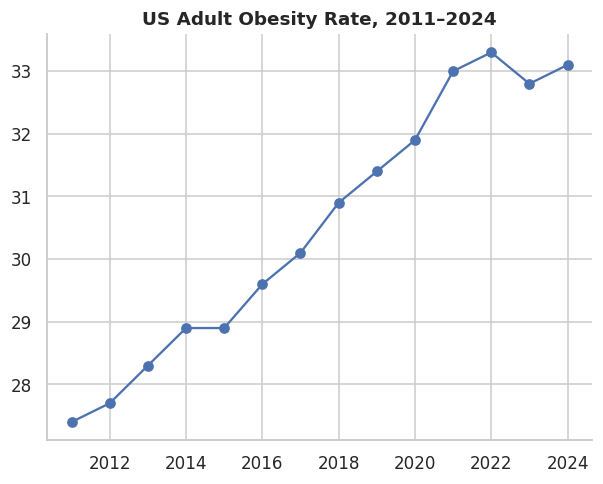

In [42]:
#US Adult Obesity Rate, 2011–2024
trend = df[(df["state_abbr"]=="US") & (df["indicator"]=="obesity")
           & (df["group_type"]=="Total")]
plt.plot(trend["year"], trend["value"], marker="o")
plt.title("US Adult Obesity Rate, 2011–2024")

One in Three U.S. Adults Now Has Obesity, Up from About One in Four in 2011. Between 2011 and 2024, adult obesity in the U.S. rose from 27.4% to 33.1%, an increase of 5.7 percentage points. The rate peaked at 33.3% in 2022 and has stayed close to that level since. Roughly one in three American adults now has obesity.

##Q. What are the states with the highest and lowest obesity rates?

Chart 2:


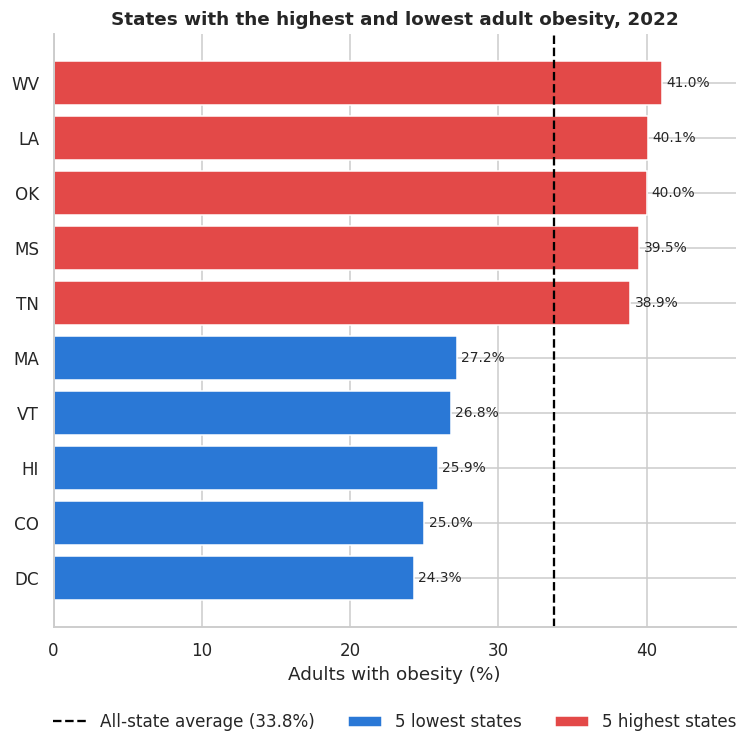

Average 33.8% | range 24.3% (DC) to 41.0% (WV)
States at 35%+: 22


In [43]:
ranked = eda[['State', 'PCT_OBESE_ADULTS22']].sort_values('PCT_OBESE_ADULTS22')
extremes = pd.concat([ranked.head(5), ranked.tail(5)])
avg = eda['PCT_OBESE_ADULTS22'].mean()

fig, ax = plt.subplots(figsize=(8, 7))
low, high = extremes.head(5), extremes.tail(5)
ax.barh(low['State'], low['PCT_OBESE_ADULTS22'], color=DOWN, label='5 lowest states')
ax.barh(high['State'], high['PCT_OBESE_ADULTS22'], color=UP, label='5 highest states')
ax.axvline(avg, color='black', linestyle='--', linewidth=1.5, label=f'All-state average ({avg:.1f}%)')
for st, v in zip(extremes['State'], extremes['PCT_OBESE_ADULTS22']):
    ax.text(v + 0.3, st, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlim(0, 46)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
ax.set(title='States with the highest and lowest adult obesity, 2022',
       xlabel='Adults with obesity (%)', ylabel='')
plt.show()

print(f'Average {avg:.1f}% | range {ranked.iloc[0, 1]}% ({ranked.iloc[0, 0]}) to {ranked.iloc[-1, 1]}% ({ranked.iloc[-1, 0]})')
print('States at 35%+:', (eda['PCT_OBESE_ADULTS22'] >= 35).sum())

A national average, however, says nothing about where obesity is concentrated. When we break it down by state, the differences are striking. In 2022, West Virginia’s rate was 41.0%, compared with 24.3% in Washington, DC. Even excluding DC, the gap between West Virginia and Colorado (25.0%) is 16 percentage points. The highest-obesity states cluster in the South and Appalachia, the lowest in the West and Northeast, and 22 states have rates of 35% or higher. This raises our first question: why does obesity depend so much on where Americans live?




## Q. Which demographic groups have the highest adult obesity rates and does income separate them as much as race, gender and education?

Chart 3 & 4:


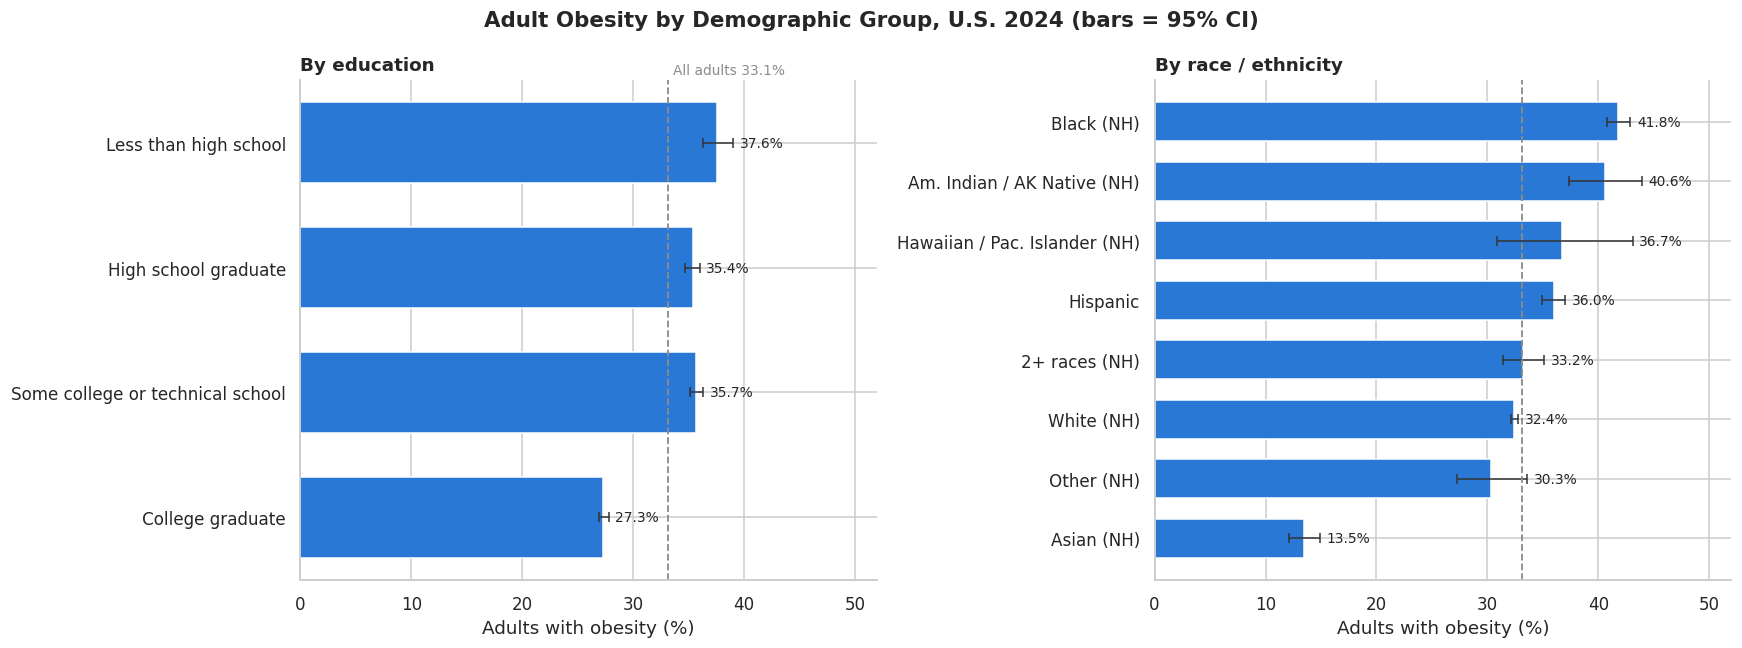

In [44]:
#Obesity by Education and Race/Ethnicity (2024)

year = 2024

# Get national average for reference line
total = national("obesity", "Total", year)
total_val = total["value"].iloc[0]

#Panel 1: Education
edu_data = national("obesity", "Education", year).copy()
edu_data = edu_data.set_index("group").loc[EDU_ORDER].reset_index()
edu_data["group"] = edu_data["group"].map(esc)

#Panel 2: Race/Ethnicity
race_data = national("obesity", "Race/Ethnicity", year).copy()
race_data["group"] = race_data["group"].map(RACE_SHORT)
race_data = race_data.sort_values("value", ascending=False)

fig, (ax_edu, ax_race) = plt.subplots(1, 2, figsize=(16, 6))

# Education subplot
ax_edu.barh(edu_data["group"], edu_data["value"], color=BLUE, height=0.65)
ax_edu.errorbar(edu_data["value"], edu_data["group"],
                xerr=[edu_data["value"] - edu_data["ci_low"],
                      edu_data["ci_high"] - edu_data["value"]],
                fmt="none", ecolor="#333333", elinewidth=1, capsize=3)

for i in range(len(edu_data)):
    val = edu_data["value"].iloc[i]
    ci_hi = edu_data["ci_high"].iloc[i]
    ax_edu.text(ci_hi + 0.6, i, f"{val:.1f}%", va="center", fontsize=9)

ax_edu.axvline(total_val, ls="--", color=GRAY, lw=1.2)
ax_edu.invert_yaxis()
ax_edu.set_title("By education", loc="left", fontsize=12)
ax_edu.set_xlim(0, 52)
ax_edu.set_xlabel("Adults with obesity (%)")
ax_edu.set_ylabel("")
ax_edu.text(total_val + 0.5, -0.55,
            f"All adults {total_val:.1f}%", color=GRAY, fontsize=9)

# Race/Ethnicity subplot
ax_race.barh(race_data["group"], race_data["value"], color=BLUE, height=0.65)
ax_race.errorbar(race_data["value"], race_data["group"],
                 xerr=[race_data["value"] - race_data["ci_low"],
                       race_data["ci_high"] - race_data["value"]],
                 fmt="none", ecolor="#333333", elinewidth=1, capsize=3)
for i in range(len(race_data)):
    val = race_data["value"].iloc[i]
    ci_hi = race_data["ci_high"].iloc[i]
    ax_race.text(ci_hi + 0.6, i, f"{val:.1f}%", va="center", fontsize=9)

ax_race.axvline(total_val, ls="--", color=GRAY, lw=1.2)
ax_race.invert_yaxis()
ax_race.set_title("By race / ethnicity", loc="left", fontsize=12)
ax_race.set_xlim(0, 52)
ax_race.set_xlabel("Adults with obesity (%)")
ax_race.set_ylabel("")

fig.suptitle(f"Adult Obesity by Demographic Group, U.S. {year} (bars = 95% CI)",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

The differences are large. Obesity rises from 20.9% among adults aged 18–24 to 39.0% at ages 45–54. It ranges from 13.5% among Asian adults to 41.8% among Black adults. College graduates (27.3%) have much lower rates than adults without a high school diploma (37.6%). Income is the exception: the differences across income groups are much smaller than across age, race or education. This becomes central to our story later.

## Q. Do high obesity states differ from low obesity states at every age, or only among older adults?

Chart 5:

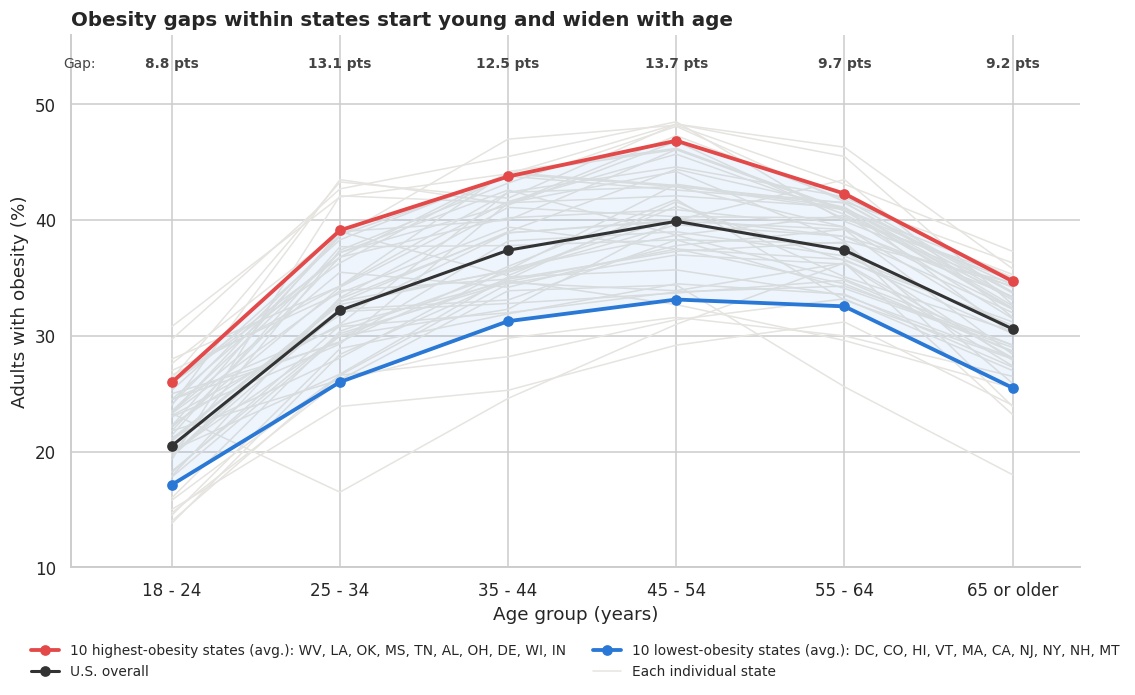

In [45]:
year = 2022
tot = state_table(year)["obesity"].sort_values()
lowest, highest = tot.index[:10], tot.index[-10:]
age = (df[(df["year"] == year) & (df["group_type"] == "Age (years)") & (df["indicator"] == "obesity")
          & (df["state_abbr"].isin(STATES))]
       .pivot(index="state_abbr", columns="group", values="value")[AGE_ORDER])
us_age = national("obesity", "Age (years)", year).set_index("group")["value"][AGE_ORDER]
hi_mean, lo_mean = age.loc[highest].mean(), age.loc[lowest].mean()
x = range(len(AGE_ORDER))

fig, ax = plt.subplots(figsize=(11, 6.5))
for s in age.index:
    ax.plot(x, age.loc[s], color=LIGHT, lw=1, zorder=1)
ax.fill_between(x, lo_mean, hi_mean, color=BLUE, alpha=0.07, zorder=2)
ax.plot(x, hi_mean, color=RED, lw=2.5, marker="o", zorder=4, label=f"10 highest-obesity states (avg.): {', '.join(highest[::-1])}")
ax.plot(x, us_age, color="#333333", lw=2, marker="o", zorder=4, label="U.S. overall")
ax.plot(x, lo_mean, color=BLUE, lw=2.5, marker="o", zorder=4, label=f"10 lowest-obesity states (avg.): {', '.join(lowest)}")
for i in x:
    ax.text(i, 53.5, f"{hi_mean.iloc[i] - lo_mean.iloc[i]:.1f} pts", ha="center", va="center",
            fontsize=9, color="#444444", fontweight="bold")
ax.text(-0.45, 53.5, "Gap:", ha="right", va="center", fontsize=9, color="#444444")
ax.plot([], [], color=LIGHT, lw=1, label="Each individual state")
ax.set_xticks(list(x)); ax.set_xticklabels(AGE_ORDER)
ax.set_xlim(-0.6, len(AGE_ORDER) - 0.6)
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Adults with obesity (%)")
ax.set_title(f"Obesity gaps within states start young and widen with age", loc="left", fontsize=13)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
ax.set_ylim(10, 56)
fig.tight_layout()
plt.show()

The strongest test is to compare people of the same age in different states. Among 18–24 year-olds, the ten highest-obesity states are already about 9 points higher than the ten lowest. By middle age the gap approaches 14 points. Because we compare the same age groups, the gap cannot be explained by some states having older populations. The geographic divide appears from early adulthood, not only later in life. If differences in population makeup cannot fully explain the geographic gap, what else differs between states? One candidate is income.

## Q. Do wealthier states have lower adults obesity rates?

Chart 6:



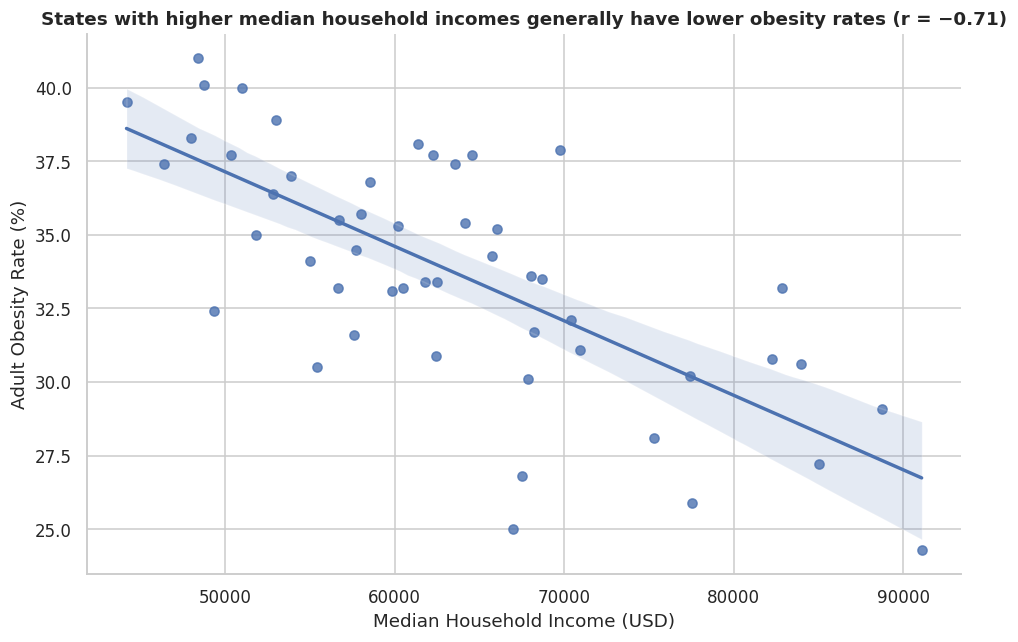

In [46]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=state_analysis,
    x="median_household_income_2021",
    y="obesity_rate"
)

plt.title("States with higher median household incomes generally have lower obesity rates (r = −0.71)")
plt.xlabel("Median Household Income (USD)")
plt.ylabel("Adult Obesity Rate (%)")
plt.tight_layout()
plt.show()

Across states, income matters. States with higher median household incomes have substantially lower obesity (r = −0.71). This is the strongest relationship in our state-level data.

## Q. Does obesity still differ between states when we compare people in the same income bracket?

Chart 7 & 8:



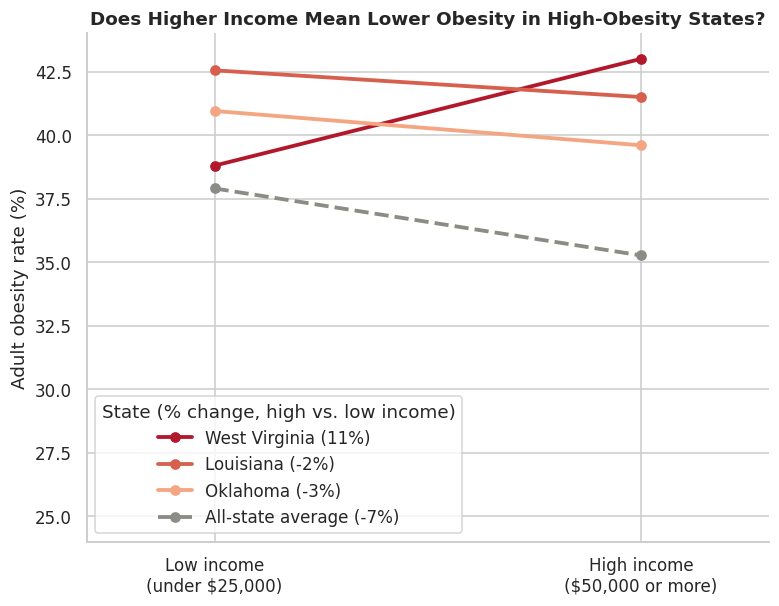

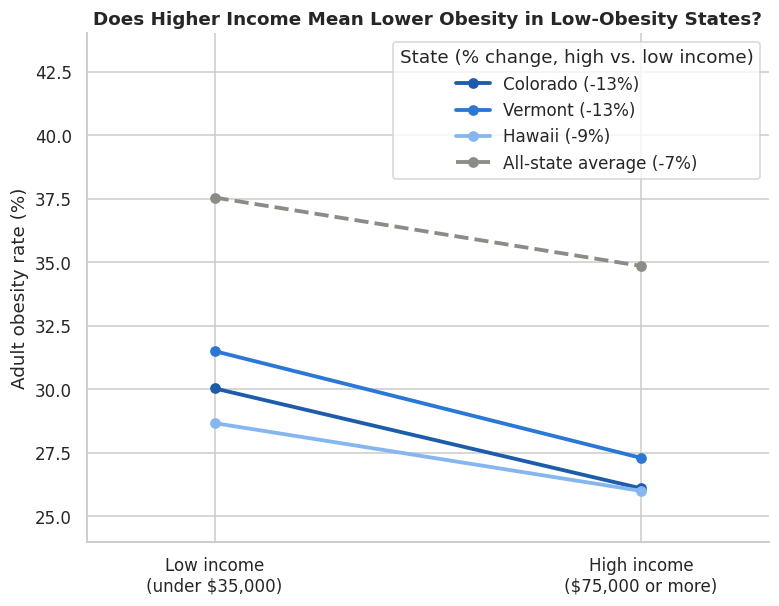

In [47]:
income = df[(df['year'] == 2022) & (df['indicator'] == 'obesity') & (df['group_type'] == 'Income')
            & (df['group'] != 'Data not reported') & (df['state_abbr'].isin(STATES))]
table = income.pivot_table(index='group', columns='state_abbr', values='value')
table['AVG'] = table.mean(axis=1)                    # all-state average

# Chart 1: high-obesity states
low = table.loc[['Less than $15,000', '$15,000 - $24,999']].mean()
high = table.loc[['$50,000 - $74,999', '$75,000 or greater']].mean()
change = ((high / low - 1) * 100).round().astype(int)

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [low['WV'], high['WV']], marker='o', linewidth=2.5, color="#b2182b", label='West Virginia (' + str(change['WV']) + '%)')
plt.plot([0, 1], [low['LA'], high['LA']], marker='o', linewidth=2.5, color="#d6604d", label='Louisiana (' + str(change['LA']) + '%)')
plt.plot([0, 1], [low['OK'], high['OK']], marker='o', linewidth=2.5, color="#f4a582", label='Oklahoma (' + str(change['OK']) + '%)')
plt.plot([0, 1], [low['AVG'], high['AVG']], marker='o', linewidth=2.5, color="#8c8b86", linestyle='--', label='All-state average (' + str(change['AVG']) + '%)')
plt.xticks([0, 1], ['Low income\n(under $25,000)', 'High income\n($50,000 or more)'])
plt.xlim(-0.3, 1.3)
plt.ylim(24, 44)
plt.ylabel('Adult obesity rate (%)')
plt.title('Does Higher Income Mean Lower Obesity in High-Obesity States?')
plt.legend(title='State (% change, high vs. low income)')
plt.show()

# Chart 2: low-obesity states
low = table.loc[['Less than $15,000', '$15,000 - $24,999', '$25,000 - $34,999']].mean()
high = table.loc['$75,000 or greater']
change = ((high / low - 1) * 100).round().astype(int)

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [low['CO'], high['CO']], marker='o', linewidth=2.5, color="#1c5cab", label='Colorado (' + str(change['CO']) + '%)')
plt.plot([0, 1], [low['VT'], high['VT']], marker='o', linewidth=2.5, color="#2a78d6", label='Vermont (' + str(change['VT']) + '%)')
plt.plot([0, 1], [low['HI'], high['HI']], marker='o', linewidth=2.5, color="#86b6ef", label='Hawaii (' + str(change['HI']) + '%)')
plt.plot([0, 1], [low['AVG'], high['AVG']], marker='o', linewidth=2.5, color="#8c8b86", linestyle='--', label='All-state average (' + str(change['AVG']) + '%)')
plt.xticks([0, 1], ['Low income\n(under $35,000)', 'High income\n($75,000 or more)'])
plt.xlim(-0.3, 1.3)
plt.ylim(24, 44)
plt.ylabel('Adult obesity rate (%)')
plt.title('Does Higher Income Mean Lower Obesity in Low-Obesity States?')
plt.legend(title='State (% change, high vs. low income)')
plt.show()

This is the central finding of our project. A state’s median income strongly predicts its obesity rate, yet within states, residents of every income bracket share similar levels. That pattern suggests state income may be acting as a marker of something residents share, regardless of their own earnings.

We should be careful here. Income brackets are broad: “$75,000 or more” may include more very high earners in Colorado than in Louisiana, and the same income buys different things where living costs differ. People in the same bracket also differ in age, education and occupation. So we cannot conclude that place matters more than income. We can conclude that individual income bracket alone cannot explain why obesity differs so much between states.

What do residents of a state share? We look first at the food environment.


## Q. Which parts of the food environment are associated with adult obesity across states?

Chart 9:


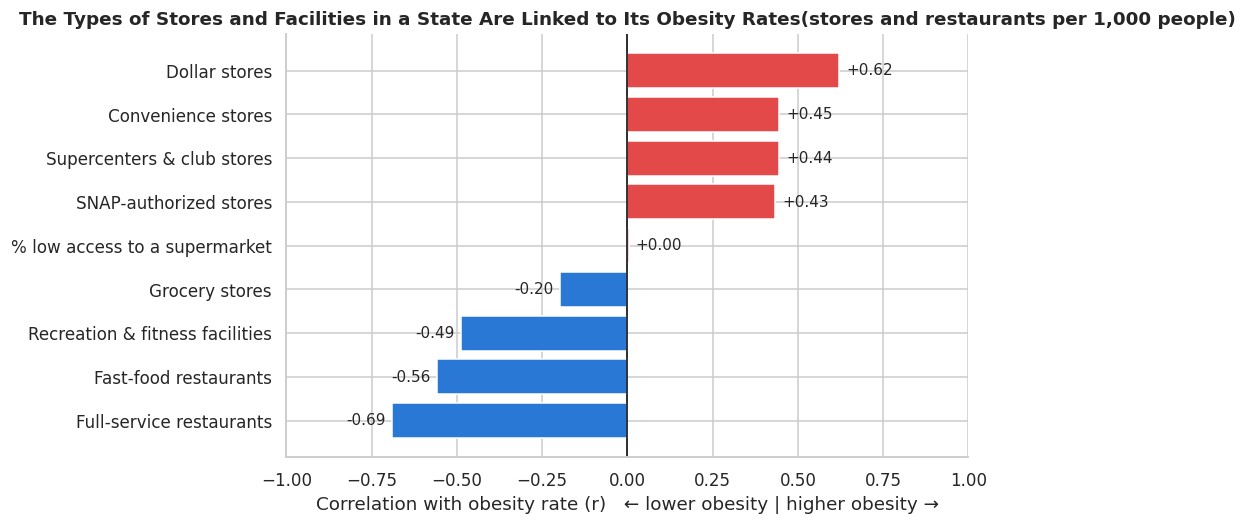

Variable_Code
Full-service restaurants          -0.69
Fast-food restaurants             -0.56
Recreation & fitness facilities   -0.49
Grocery stores                    -0.20
% low access to a supermarket      0.00
SNAP-authorized stores             0.43
Supercenters & club stores         0.44
Convenience stores                 0.45
Dollar stores                      0.62
Name: PCT_OBESE_ADULTS22, dtype: float64


In [48]:
factors = {
    'DSPTH20':           'Dollar stores',
    'CONVSPTH20':        'Convenience stores',
    'SUPERCPTH20':       'Supercenters & club stores',
    'SNAPSPTH23':        'SNAP-authorized stores',
    'GROCPTH20':         'Grocery stores',
    'PCT_LACCESS_POP19': '% low access to a supermarket',
    'RECFACPTH20':       'Recreation & fitness facilities',
    'FFRPTH20':          'Fast-food restaurants',
    'FSRPTH20':          'Full-service restaurants',
}
corr = (eda[list(factors) + ['PCT_OBESE_ADULTS22']].corr()['PCT_OBESE_ADULTS22']
        .drop('PCT_OBESE_ADULTS22').rename(factors).sort_values())

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(corr.index, corr.values, color=[UP if v > 0 else DOWN for v in corr])
ax.axvline(0, color='black', linewidth=1)
for name, v in corr.items():
    ax.text(v + (0.02 if v > 0 else -0.02), name, f'{v:+.2f}', va='center',
            ha='left' if v > 0 else 'right', fontsize=10)
ax.set_xlim(-1, 1)
ax.set(title='The Types of Stores and Facilities in a State Are Linked to Its Obesity Rates(stores and restaurants per 1,000 people)',
       xlabel='Correlation with obesity rate (r)   ← lower obesity | higher obesity →', ylabel='')
plt.show()
print(corr.round(2))


States with more dollar stores per 1,000 residents have higher obesity (r = +0.62). Convenience stores (+0.45), supercenters (+0.44) and SNAP-authorized stores (+0.43) show the same direction.

Restaurants show the opposite pattern. States with more full-service restaurants have lower obesity (r = −0.69), and so do states with more fast-food restaurants (r = −0.56). If fast food simply caused obesity, we would expect the reverse.

Q. How do the food environments within certain states differ from the average and what is their impact on obesity rates?


In [49]:
# The food-environment and economic variables, with readable names
PROFILE = {'GROCPTH20': 'Grocery stores/1k', 'CONVSPTH20': 'Convenience stores/1k', 'DSPTH20': 'Dollar stores/1k',
           'FFRPTH20': 'Fast-food/1k', 'FSRPTH20': 'Full-service restaurants/1k', 'RECFACPTH20': 'Recreation facilities/1k',
           'SNAPSPTH23': 'SNAP stores/1k', 'MEDHHINC21': 'Median household income', 'POVRATE21': 'Poverty rate (%)',
           'PCT_OBESE_ADULTS22': 'Obesity rate (%)'}
profile = eda.set_index('State')[list(PROFILE)].rename(columns=PROFILE)   # 51 states x 10 variables

# Direction of each variable across the 51 states (the Chart 5 correlations, plus income and poverty)
direction = profile.corr()['Obesity rate (%)']
CASES = ['WV', 'LA', 'VT', 'CO']
STATE_NAME = {'WV': 'West Virginia', 'LA': 'Louisiana', 'VT': 'Vermont', 'CO': 'Colorado'}
BENCH = 'All-state average'

# The table for our four states and the all-state average
profile_table = profile.loc[CASES].T.rename(columns=STATE_NAME)
profile_table[BENCH] = profile.mean()
print(profile_table.round(2))
print('\nCorrelation with obesity across the 51 states (as in Chart 5):')
print(direction.drop('Obesity rate (%)').round(2))

def profile_chart(state):
    """Horizontal bars: how far one state sits from the all-state average on each variable (% difference).
    Red = the difference goes with higher obesity in Chart 5; blue = it goes with lower obesity; gray = obesity itself."""
    diff = (profile.loc[state] - profile.mean()) / profile.mean() * 100
    colors = []
    for var in diff.index:
        if var == 'Obesity rate (%)':
            colors.append(GRAY)
        elif (diff[var] > 0) == (direction[var] > 0):      # same sign as the correlation = higher-obesity direction
            colors.append(RED)
        else:
            colors.append(BLUE)
    plt.figure(figsize=(9, 5))
    plt.barh(diff.index, diff, color=colors)
    plt.axvline(0, color='k', linewidth=1)
    for i, v in enumerate(diff):
        plt.text(v + (2 if v >= 0 else -2), i, f"{v:+.0f}%", va='center', ha='left' if v >= 0 else 'right', fontsize=10)
    plt.xlim(-70, 110)
    plt.title(
        f"{STATE_NAME[state]}: How Obesity, Income, and Food Environment Compare to the State Average",
        loc='left',
        fontsize=11
    )
    plt.xlabel('% Difference from All-State Average')
    plt.grid(True, axis='x')
    plt.tight_layout()

State                        West Virginia  Louisiana   Vermont  Colorado  \
Variable_Code                                                               
Grocery stores/1k                     0.20       0.20      0.36      0.27   
Convenience stores/1k                 0.56       0.62      0.75      0.52   
Dollar stores/1k                      0.26       0.33      0.17      0.11   
Fast-food/1k                          0.63       0.63      0.62      0.91   
Full-service restaurants/1k           0.65       0.47      0.99      1.71   
Recreation facilities/1k              0.10       0.11      0.15      0.18   
SNAP stores/1k                        1.31       1.04      1.02      0.89   
Median household income           48429.80   48784.28  67507.14  66994.42   
Poverty rate (%)                     18.06      21.62     10.44     12.57   
Obesity rate (%)                     41.00      40.10     26.80     25.00   

State                        All-state average  
Variable_Code             

Chart 10: West Virginia

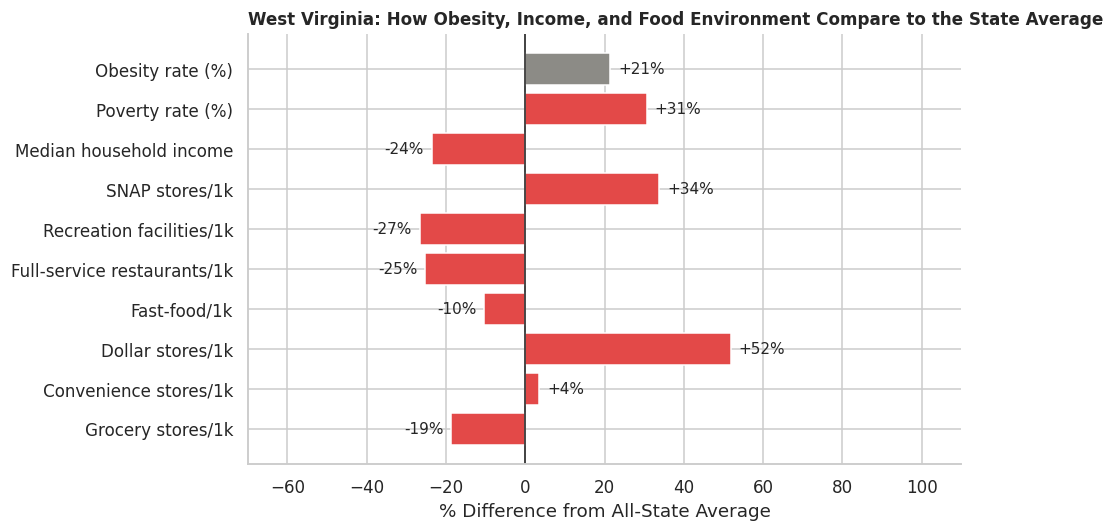

In [50]:
profile_chart('WV')
plt.show()

West Virginia’s obesity is 21% above average, and it is red on all nine measures, led by 52% more dollar stores, 34% more SNAP-authorized stores and 31% more poverty. This shows that the highest-obesity state has the full set of conditions that go with higher obesity, not just one of them.

Chart 11: Vermont

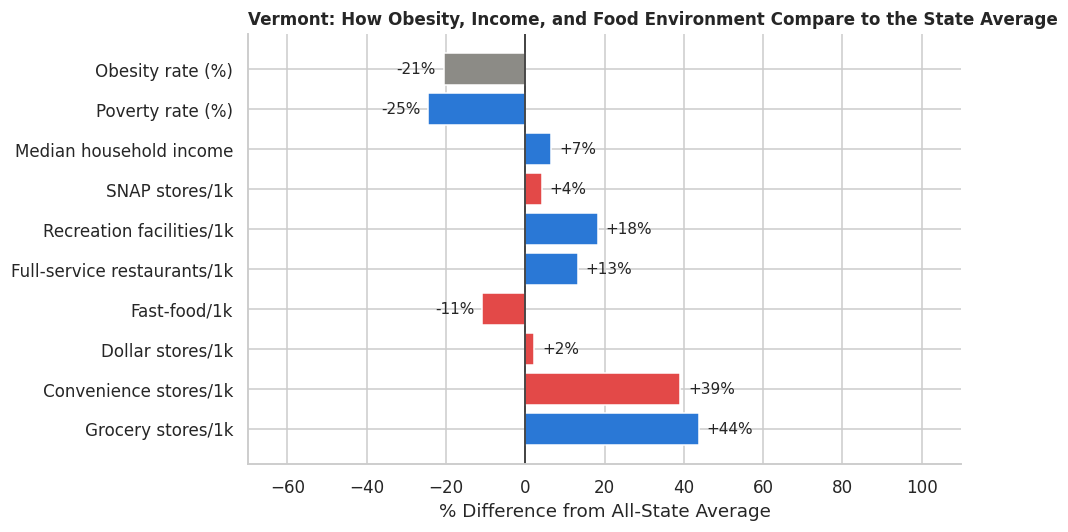

In [51]:
profile_chart('VT')
plt.show()

Vermont’s obesity is 21% below average, but its profile is more mixed than the other two: it has 39% more convenience stores than average, yet it also has 25% less poverty, 44% more grocery stores and 18% more recreation facilities. This shows that one higher-obesity marker doesn’t decide a state’s outcome; what matters is the overall mix, which in Vermont leans clearly toward lower obesity.

Chart 12: Colorado

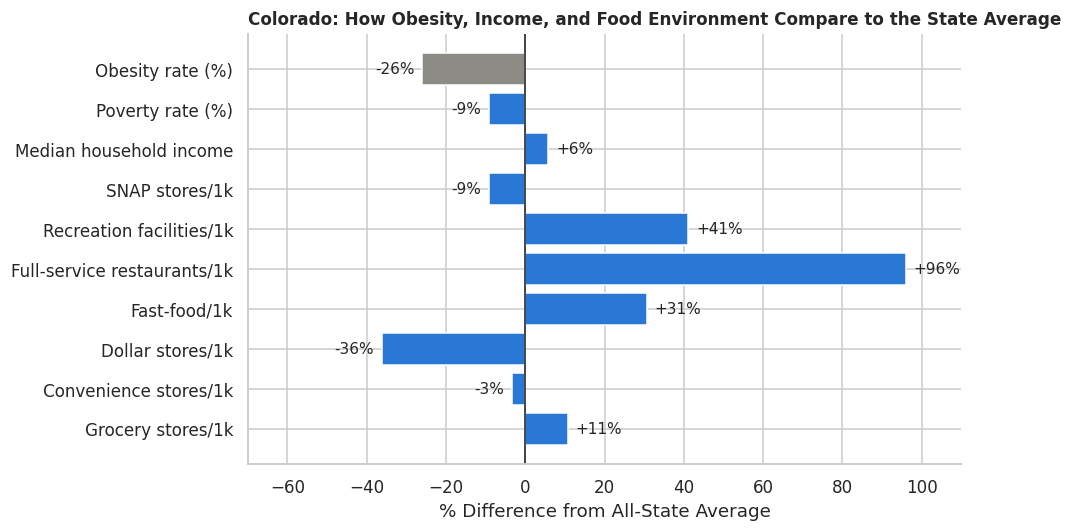

In [52]:
profile_chart('CO')
plt.show()

Colorado is the opposite of West Virginia: obesity is 26% below average and every measure is blue, led by nearly double the full-service restaurants (+96%) and 41% more recreation facilities. Its income is only 6% above average, which supports our finding that money alone doesn’t explain why obesity differs so much between states.

Q. Do higher income individuals in high obesity states eat and exercise better than their lower income adults, and does it show in their obesity rates?

Chart 13:

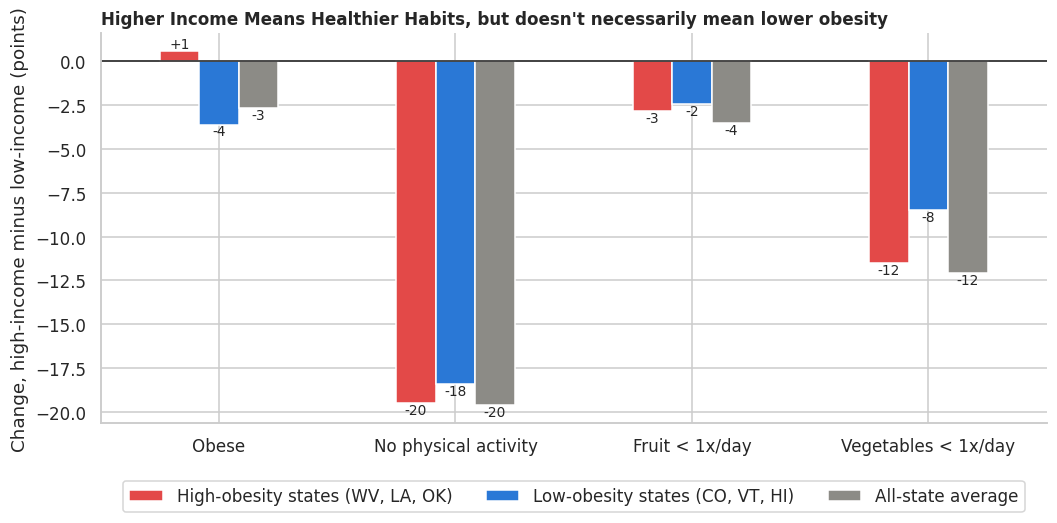

                                  Obese  No physical activity  Fruit < 1x/day  \
High-obesity states (WV, LA, OK)    0.6                 -19.5            -2.8   
Low-obesity states (CO, VT, HI)    -3.6                 -18.4            -2.4   
All-state average                  -2.6                 -19.6            -3.5   

                                  Vegetables < 1x/day  
High-obesity states (WV, LA, OK)                -11.5  
Low-obesity states (CO, VT, HI)                  -8.5  
All-state average                               -12.1  


In [53]:
HIGH_STATES = ['WV', 'LA', 'OK']
LOW_STATES = ['CO', 'VT', 'HI']

MEASURES = {'obesity': 'Obese','no_activity': 'No physical activity', 'fruit_lt1_daily': 'Fruit < 1x/day','veg_lt1_daily': 'Vegetables < 1x/day'}

YEAR = {'obesity': 2022,'no_activity': 2022, 'fruit_lt1_daily': 2021,'veg_lt1_daily': 2021}

results = pd.DataFrame(index=['High-obesity states (WV, LA, OK)', 'Low-obesity states (CO, VT, HI)','All-state average'])

for code in MEASURES:
    rows = df[(df['year'] == YEAR[code]) & (df['indicator'] == code) & (df['group_type'] == 'Income') & (df['group'] != 'Data not reported') &(df['state_abbr'].isin(STATES))]

    table = rows.pivot_table(index='group',columns='state_abbr', values='value')

    low_a = table.loc[['Less than $15,000', '$15,000 - $24,999']].mean()

    high_a = table.loc[['$50,000 - $74,999', '$75,000 or greater']].mean()

    low_b = table.loc[['Less than $15,000', '$15,000 - $24,999','$25,000 - $34,999']].mean()

    high_b = table.loc['$75,000 or greater']

    results.loc['High-obesity states (WV, LA, OK)', MEASURES[code]] = (high_a[HIGH_STATES] - low_a[HIGH_STATES]).mean()

    results.loc['Low-obesity states (CO, VT, HI)', MEASURES[code]] = (high_b[LOW_STATES] - low_b[LOW_STATES]).mean()

    results.loc['All-state average', MEASURES[code]] = (high_a - low_a).mean()

# Same chart as before
ax = results.T.plot(kind='bar',figsize=(10, 5),rot=0,color=[RED, BLUE, GRAY])

for bars in ax.containers:
    ax.bar_label(bars, fmt='%+.0f', fontsize=9)

plt.axhline(0, color='k', linewidth=1)

plt.title("Higher Income Means Healthier Habits, but doesn't necessarily mean lower obesity",
    loc='left',
    fontsize=11)

plt.ylabel('Change, high-income minus low-income (points)')

plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), ncol=3)
plt.tight_layout()
plt.show()

print(results.round(1))

In the higher-obesity states, higher-income adults are just as active and eat similar amounts of vegetables as lower-income adults in the rest of the country.


##Q. Are the groups that are the least likely to be obese (college grads, younger adults and high income earners) still above the national average in the high obesity states?

Chart 14:

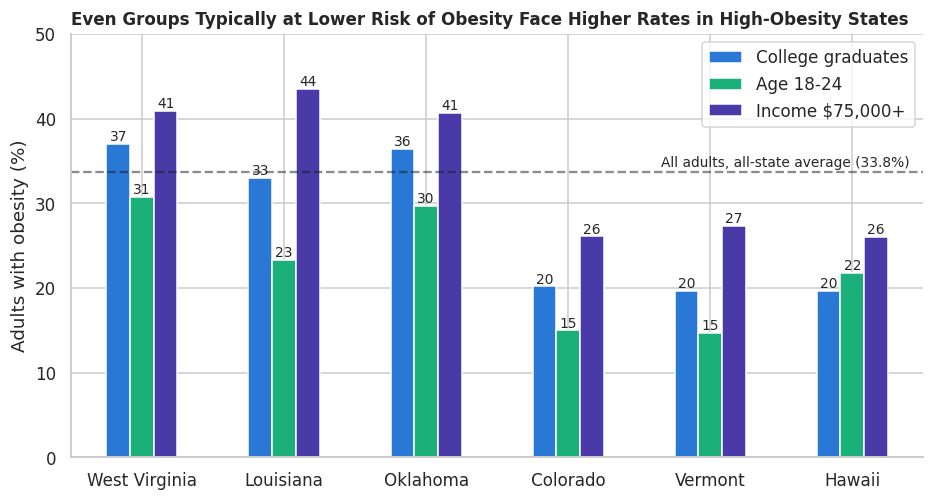

In [54]:
population_groups = [ ('Education', 'College graduate', 'College graduates'), ('Age (years)', '18 - 24', 'Age 18-24'),('Income', '$75,000 or greater', 'Income $75,000+')]

obesity_by_group = pd.DataFrame(index=HIGH_STATES + LOW_STATES)

for category, population, label in population_groups:
    filtered_data = df[(df['year'] == 2022) & (df['indicator'] == 'obesity') & (df['group_type'] == category) & (df['group'] == population)]
    obesity_by_group[label] = filtered_data.set_index('state_abbr')['value']

obesity_by_group.index = ['West Virginia', 'Louisiana', 'Oklahoma', 'Colorado', 'Vermont', 'Hawaii']

# Average obesity rate across all states
average_obesity_rate = df[(df['year'] == 2022) & (df['indicator'] == 'obesity') & (df['group_type'] == 'Total') & (df['state_abbr'].isin(STATES))]['value'].mean()

# Create bar chart
chart = obesity_by_group.plot(kind='bar', figsize=(10, 5), rot=0, color=[BLUE, AQUA, VIOLET])


# Add values above bars
for bars in chart.containers:
    chart.bar_label(bars, fmt='%.0f', fontsize=9)

# Add average obesity reference line
plt.axhline(average_obesity_rate, color='k',linestyle='--',alpha=0.5)

plt.text(5.4, average_obesity_rate + 0.5, 'All adults, all-state average (' + str(round(average_obesity_rate, 1)) + '%)',ha='right',fontsize=9)

plt.title('Even Groups Typically at Lower Risk of Obesity Face Higher Rates in High-Obesity States',loc='left',fontsize=11)

plt.ylabel('Adults with obesity (%)')
plt.xlabel('')
plt.ylim(0, 50)
plt.legend(loc='upper right')
plt.show()

In the lower obesity states, college graduates, younger adults, and higher income earners are all well below the national average in terms of obesity. In the higher obesity states, the same groups are mostly above the average, showing that people who are usually the least obese are heavy in these states.



##Q. How well do food environment factors alone explain state-level obesity and which state does the model miss?

Chart 15:

Fitted on 50 states.  R-squared = 0.69   mean absolute error = 1.7 points

Obesity rate (%) = 32.17
                      +6.89 x Dollar stores
                      +0.99 x Convenience stores
                    +113.39 x Supercenters & club stores
                      +4.06 x SNAP-authorized stores
                      +0.06 x % low access to a supermarket
                      -4.34 x Grocery stores
                     +18.02 x Recreation & fitness facilities
                      -5.16 x Fast-food restaurants
                      -7.74 x Full-service restaurants

The equation at the all-state average:
                                 all-state average value  coefficient  contribution (points)
Variable_Code                                                                               
Dollar stores                                       0.17         6.89                   1.17
Convenience stores                                  0.54         0.99                   0.54
Supercenter

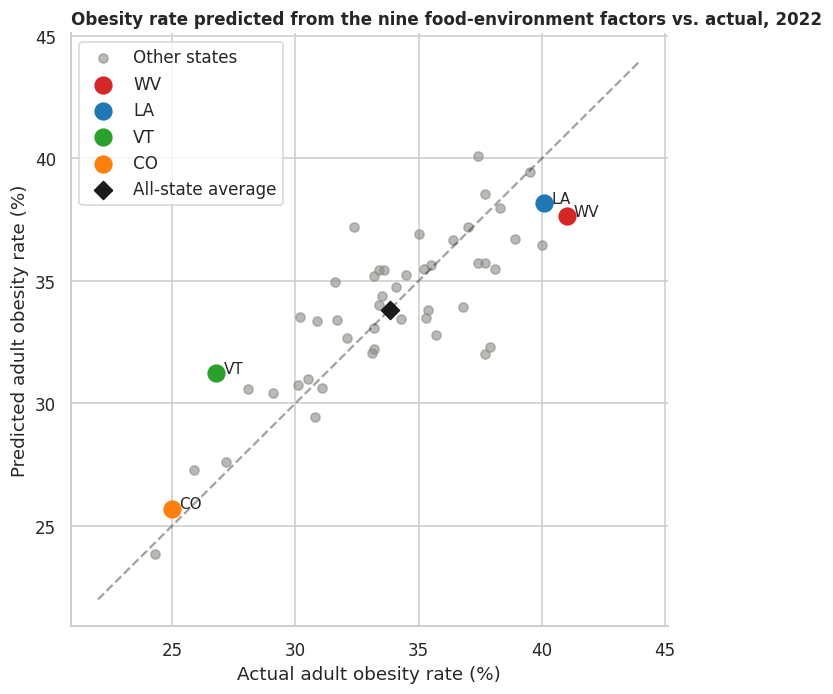


Our four states:
       actual  predicted  error
State                          
WV       41.0       37.6    3.4
LA       40.1       38.2    1.9
VT       26.8       31.2   -4.4
CO       25.0       25.7   -0.7


In [55]:
CHART5 = {'DSPTH20': 'Dollar stores', 'CONVSPTH20': 'Convenience stores', 'SUPERCPTH20': 'Supercenters & club stores',
          'SNAPSPTH23': 'SNAP-authorized stores', 'PCT_LACCESS_POP19': '% low access to a supermarket',
          'GROCPTH20': 'Grocery stores', 'RECFACPTH20': 'Recreation & fitness facilities',
          'FFRPTH20': 'Fast-food restaurants', 'FSRPTH20': 'Full-service restaurants'}
model_data = eda.set_index('State')[list(CHART5) + ['PCT_OBESE_ADULTS22']].rename(columns=CHART5).dropna()
X = model_data.drop(columns='PCT_OBESE_ADULTS22')          # the nine Chart 5 factors (per 1,000 people, or %)
y = model_data['PCT_OBESE_ADULTS22']                        # adult obesity rate, 2022

COLORS = dict(zip(CASES, ['#d62728', '#1f77b4', '#2ca02c', '#ff7f0e'])); STATE_NAME = {s: s for s in CASES}

model = LinearRegression()
model.fit(X, y)
predicted = model.predict(X)
print(f"Fitted on {len(y)} states.  R-squared = {model.score(X, y):.2f}   "
      f"mean absolute error = {mean_absolute_error(y, predicted):.1f} points")


# The equation
print(f"\nObesity rate (%) = {model.intercept_:.2f}")
for name, coef in zip(X.columns, model.coef_):
    print(f"                   {coef:+8.2f} x {name}")

# What the equation gives for the average state (each term = coefficient x the all-state average value)
contribution = pd.DataFrame({'all-state average value': X.mean(), 'coefficient': model.coef_})
contribution['contribution (points)'] = contribution['all-state average value'] * contribution['coefficient']
print('\nThe equation at the all-state average:')
print(contribution.round(2).to_string())
print(f"intercept {model.intercept_:.2f} + contributions {contribution['contribution (points)'].sum():.2f} "
      f"= {model.intercept_ + contribution['contribution (points)'].sum():.1f}%  (actual all-state average: {y.mean():.1f}%)")

# Predicted vs. actual, with our four states marked
plt.figure(figsize=(7, 7))
plt.scatter(y, predicted, color=GRAY, alpha=0.6, label='Other states')
for s in CASES:
    plt.scatter(y[s], predicted[list(y.index).index(s)], color=COLORS[s], s=120, label=STATE_NAME[s])
    plt.text(y[s] + 0.3, predicted[list(y.index).index(s)], s, fontsize=10)
plt.scatter(y.mean(), y.mean(), marker='D', color='k', s=70, label=BENCH)
plt.plot([22, 44], [22, 44], color='k', linestyle='--', alpha=0.4)      # perfect-prediction line
plt.title('Obesity rate predicted from the nine food-environment factors vs. actual, 2022', loc='left', fontsize=11)
plt.xlabel('Actual adult obesity rate (%)')
plt.ylabel('Predicted adult obesity rate (%)')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

print('\nOur four states:')
print(pd.DataFrame({'actual': y, 'predicted': predicted, 'error': y - predicted}, index=y.index).loc[CASES].round(1))

Using the 9 food environment factors, we were able to predict a state's obesity rate fairly well (R-squared = 0.69). They underpredict and overpredict certain states, suggesting other factors are at play.

---

# Conclusion
Adult obesity in the United States is shaped not just by individual choices or income, but by where people live.

Nationally, adult obesity rose from 27.4% in 2011 to 33.1% in 2024, and one in three American adults now has obesity. In 2022, rates ranged from 24.3% in Washington, DC, to 41.0% in West Virginia, and 22 states had rates of 35% or higher, mostly in the South and Appalachia. These differences appear early in life: among adults aged 18–24, the highest-obesity states were already about 9 points higher than the lowest, and the gap grew to nearly 14 points by middle age.

Income tells a powerful story. Wealthier states have lower obesity (r = −0.71), the strongest relationship in our state-level data. Yet adults in the same income bracket show a 17.4-point gap by state, and in high-obesity states, even higher earners, college graduates, and young adults remain above the national average. This suggests that a state’s wealth reflects conditions shared by everyone who lives there.

Those shared conditions show up in the food environment and in opportunities to be active. States with more dollar stores have higher obesity (r = +0.62), while states with more full-service restaurants (r = −0.69) and more recreation and fitness facilities (r = −0.49) have lower obesity. Food access matters most for specific communities: low access among American Indian/Alaska Native residents, children, and SNAP households was linked to higher obesity.

Together, these findings show that obesity is concentrated in particular places, reaches residents at every income level in those places, and falls hardest on specific groups. Public-health departments can make the greatest impact by focusing on the highest-obesity states, reaching whole communities, and combining affordable healthy food, accessible physical activity and support for high-risk groups. They should work with funders, governments, community organizations, retailers, schools and employers. The recommendations below set out how.



#Challenges
Merging datasets with different structures. The BRFSS data is organized by state, year, and demographic group, while the Atlas data is in long format at the county level. Converting the Atlas from long to wide and aggregating counties up to states required careful handling of different variable types, some needed to be summed (counts) and others averaged (rates). Getting this wrong initially led to inflated state-level values that we had to fix.

Inconsistent variable labeling in the Atlas. Several Atlas variables were labeled as “Count” in the data dictionary but were actually per-1,000-population rates (e.g., FSRPTH20). We only discovered this after our early charts looked off, and we had to cross-check variable definitions against the ERS documentation to correct our aggregation approach.

Missing data and placeholder values. The Atlas uses sentinel codes (−9999 and −8888) for suppressed or missing data, which we had to identify and replace with NaN. Some variables, particularly in Alaska and parts of Connecticut, had high rates of missing counties, which limited our ability to do consistent county-level comparisons across all states.

Balancing the number of charts with storytelling. We generated more charts than we could include and had to decide which ones added real insight versus which ones repeated similar points.


#Risk & Limits
- Correlation, not causation. All relationships are state-level or group-level, and factors such as income, urbanization, and age are tangled together.

- Averaging and missing data. County values were averaged without population weights, and some variables were missing for many counties, especially in Alaska and Connecticut.

- Mismatched years. BRFSS and Atlas variables cover different years, and our charts use 2021, 2022, and 2024 depending on the question.
Self-reported survey data. BRFSS relies on self-reported height and weight, which tends to understate obesity.

- Small groups. Estimates for small groups and low-income brackets have wide confidence intervals.

# Future Steps
Add county-level obesity data. Our current analysis is limited to state-level obesity rates. If county-level obesity estimates become available (for example, from the CDC's PLACES dataset), we could match them directly with the Atlas food-environment variables at the county level, which would give a much more detailed picture of where interventions are most needed.

Test whether food-environment changes actually reduce obesity. Our findings are correlational. A natural next step would be to compare obesity trends before and after healthy-store programs or new recreation facilities are implemented in states or counties, to see whether the relationships we found hold up over time.

Include additional variables. Factors like public transportation access, walkability scores, healthcare availability, and food prices aren't in our current datasets but could help explain gaps between our regression model's predictions and what actually happens in states like West Virginia and Louisiana.

Weight county-to-state aggregations by population. Our state-level Atlas values are simple averages across counties. Weighting by county population would give more accurate state estimates, especially for states where a few large counties dominate the population.

---
## References
Dataset 1: https://catalog.data.gov/dataset/nutrition-physical-activity-and-obesity-behavioral-risk-factor-surveillance-system?from_hint=eyJzb3J0IjoicG9wdWxhcml0eSJ9 (under the resource 1 section)


Dataset 2: https://ers.usda.gov/data-products/food-environment-atlas/data-access-and-documentation-downloads (under the current version section)



## Generative AI Disclosure

* Used for reviewing grammar of written materials.

* Data loading setup: Claude showed us how to set up a shared Google Drive path (DATA_DIR) so the notebook works for everyone without changing file paths.

* Debugging: We used Claude to find errors when the notebook couldn't run from start to finish, like wrong column names or data being overwritten. We fixed the code and re-tested it ourselves.

* Markdown headings: Some section titles were shortened with Claude's help to make them easier to read.

* Atlas label fix: We found that some variables (e.g. FSRPTH) were labelled as Count but are actually per-1,000 rates. We asked Claude how to fix this, and followed its method to correct the labels before aggregation.

* Count vs. percent aggregation: Claude pointed out that count columns should be summed, not averaged, when rolling counties up to states. We updated the code and verified with .describe().

* The chart code is based on standard Seaborn templates. We used Claude to help adapt these templates to our datasets, such as adjusting variable names and plot parameters. We reviewed and verified the outputs ourselves. The chart ideas were our own: we created several charts and selected the ones that best highlighted patterns in our datasets.

* Chart formatting: We asked Claude to help us choose a consistent color palette and adjust chart elements like axis labels, title placement and legend positioning so the charts are easier to read and visually consistent across the notebook.

* Variable naming: Claude helped us create readable labels for Atlas variable codes (e.g. mapping DSPTH20 to "Dollar stores per 1,000") so that chart titles and axis labels are more understandable.

* Graph ideas: During our analysis, we discussed potential chart directions with Claude, such as comparing state food-environment profiles and looking at predicted vs. actual obesity. We decided which ideas to pursue and which to discard based on our own judgment and what fit our research question.

* Narrative structure: Claude helped us organize and revise the written analysis sections for clarity. The findings and interpretations are based on our own analysis of the data.

* Recommendations: We drafted our recommendations based on our analysis results. Claude helped us revise the wording and connect each recommendation to the relevant stakeholders.
